AI use: code and draft text produced with Claude (Anthropic), directed and reviewed by the team.

# Experiment B — Aqua vs S-NPP hotspot matching, Sabah

Runs top to bottom from the three files in `../data/` (never modified). Day results 2012–2022 are the primary result; see `REPORT.md` for interpretation and limits.

> **Required limit.** FIRMS CSVs contain detections only, not where a satellite looked and found nothing. A VIIRS-only detection can mean Aqua missed it, Aqua's swath did not cover it, cloud blocked it, the fire changed between passes, or matching failed. VIIRS-only is never read as a MODIS failure. The earlier ratio used Terra + Aqua; this notebook uses Aqua + S-NPP only.

## Parameters
All key choices live in the shared module below: cleaning rules (type 0; MODIS confidence ≥ 30; VIIRS n/h; Feb 2012 onward; archive rows only), primary time window `T_PRIMARY` = 15 min (5/30/60 as sensitivity), geolocation margin `MARGIN_KM` = 0.5 km, cluster link `LINK_KM` = 0.75 km, primary period ends `PRIMARY_END`.

In [1]:
# Shared parameters and loaders for Experiment B.
import os, numpy as np, pandas as pd
DATA = os.path.join(os.path.dirname(os.path.abspath(__file__)), '..', '..', 'data') if '__file__' in globals() else '../data'
OUT = os.path.join(DATA, '..', 'experiment_b')
INTER = os.path.join(OUT, 'intermediate'); FIG = os.path.join(OUT, 'figures')

# ---- parameters ----
BOX = dict(lat=(4.0, 7.5), lon=(115.3, 119.3))
MODIS_CONF_MIN = 30
VIIRS_CONF_KEEP = ('n', 'h')
OVERLAP_START = '2012-02-01'
ARCHIVE_END = '2026-08-01'      # common archive end (VIIRS archive ends 2026-07-31)
PRIMARY_END = '2023-01-01'      # primary period = Feb 2012 - Dec 2022 (Aqua overpass aligned with S-NPP)
T_PRIMARY = 15                  # minutes; sensitivity 5/30/60
MARGIN_KM = 0.5                 # geolocation margin added to each Aqua half-footprint
LINK_KM = 0.75                  # VIIRS cluster linking distance
KM_PER_DEG_LAT = 111.32
OKABE = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7']
LS = ['-', '--', ':', '-.', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

def load_raw():
    m = pd.read_csv(os.path.join(DATA, 'sabah_raw_MODIS.csv'), dtype={'version': str, 'confidence': str})
    v = pd.read_csv(os.path.join(DATA, 'sabah_raw_VIIRS.csv'), dtype={'version': str, 'confidence': str})
    for d in (m, v):
        hh, mm = d['acq_time'] // 100, d['acq_time'] % 100
        d['t'] = pd.to_datetime(d['acq_date']) + pd.to_timedelta(hh, 'h') + pd.to_timedelta(mm, 'min')
        d['nrt'] = d['type'].isna()
    m['conf_num'] = pd.to_numeric(m['confidence'], errors='coerce')
    return m, v

def clean(m, v):
    """Section-1 cleaning rules + archive only + overlap period. Aqua only for MODIS."""
    a = m[(~m.nrt) & (m.type == 0) & (m.conf_num >= MODIS_CONF_MIN) & (m.satellite == 'Aqua') & (m.t >= OVERLAP_START)].copy()
    s = v[(~v.nrt) & (v.type == 0) & (v.confidence.isin(VIIRS_CONF_KEEP)) & (v.t >= OVERLAP_START)].copy()
    return a.reset_index(drop=True), s.reset_index(drop=True)

def km_xy(lat, lon, lat0=5.75):
    """Local equirectangular projection (km). Error < 0.5% across the 3.5-degree box."""
    return (np.asarray(lon) * KM_PER_DEG_LAT * np.cos(np.radians(lat0)), np.asarray(lat) * KM_PER_DEG_LAT)

def assign_passes(df, gap_min=20):
    """Group detections of one satellite into overpasses: sorted times, new pass when gap > gap_min minutes."""
    df = df.sort_values('t')
    new = df['t'].diff().dt.total_seconds().div(60).fillna(1e9) > gap_min
    df['pass_id'] = new.cumsum()
    return df


### Matching functions
`match()` tests whether a VIIRS centre lies inside an Aqua rectangle (`scan` × `track` km, each detection's own size, plus margin) within T minutes, and records the Aqua pixel id so nothing is double counted. `add_clusters()` links VIIRS pixels of the same overpass within 750 m. A cluster is not a fire.

In [2]:
# Spatial-temporal matching of S-NPP (VIIRS) detections to Aqua pixel footprints.
import numpy as np, pandas as pd
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def _min(t): return t.values.astype('datetime64[s]').astype('int64') / 60.0

def match(a, s, T=T_PRIMARY, mode='rect', scale=1.0, margin=MARGIN_KM, radius=1.0):
    """a: Aqua df, s: VIIRS df (both with latitude, longitude, t, scan, track). Returns (s_out, a_out).
    mode 'rect': VIIRS centre inside rectangle scan*scale km E-W by track*scale km N-S around Aqua centre, plus margin km.
    mode 'radius': VIIRS centre within `radius` km of Aqua centre.
    Time rule: |dt| <= T minutes. Aqua pixel id = row position in the reset-index Aqua frame."""
    a = a.reset_index(drop=True); s = s.reset_index(drop=True)
    ax, ay = km_xy(a.latitude, a.longitude); sx, sy = km_xy(s.latitude, s.longitude)
    at, st = _min(a.t), _min(s.t)
    hx = a.scan.values * scale / 2 + margin; hy = a.track.values * scale / 2 + margin
    if mode == 'radius': hx = hy = np.full(len(a), radius)
    tree = cKDTree(np.c_[ax, ay])
    R = np.hypot(hx.max(), hy.max())
    cand = tree.query_ball_point(np.c_[sx, sy], R)
    si, ai, d = [], [], []
    for i, lst in enumerate(cand):
        if not lst: continue
        j = np.array(lst)
        ok = np.abs(at[j] - st[i]) <= T
        if mode == 'rect':
            ok &= (np.abs(ax[j] - sx[i]) <= hx[j]) & (np.abs(ay[j] - sy[i]) <= hy[j])
        else:
            ok &= np.hypot(ax[j] - sx[i], ay[j] - sy[i]) <= radius
        j = j[ok]
        si += [i] * len(j); ai += j.tolist(); d += np.hypot(ax[j] - sx[i], ay[j] - sy[i]).tolist()
    pairs = pd.DataFrame({'si': si, 'ai': ai, 'd': d})
    s = s.copy(); a = a.copy()
    s['n_cand'] = pairs.groupby('si').size().reindex(range(len(s))).fillna(0).astype(int).values
    s['matched'] = s.n_cand > 0
    best = pairs.sort_values('d').drop_duplicates('si').set_index('si')['ai']
    s['aqua_id'] = best.reindex(range(len(s))).values   # nearest-centre Aqua pixel among footprint-valid candidates
    a['n_viirs'] = pairs.groupby('ai').size().reindex(range(len(a))).fillna(0).astype(int).values
    a['has_viirs'] = a.n_viirs > 0
    # "observed" flags: any detection of the other sensor anywhere in the box within T minutes
    ats, sts = np.sort(at), np.sort(st)
    def near(x, ref):
        k = np.searchsorted(ref, x); lo = ref[np.clip(k - 1, 0, len(ref) - 1)]; hi = ref[np.clip(k, 0, len(ref) - 1)]
        return np.minimum(np.abs(x - lo), np.abs(x - hi)) <= T
    s['aqua_obs'] = near(st, ats); a['viirs_obs'] = near(at, sts)
    return s, a

def add_clusters(s, link_km=LINK_KM):
    """Connected groups of VIIRS detections from the same overpass (pass = detections <=20 min apart, same day/night flag)
    whose centres are within link_km of each other (chain linking)."""
    s = s.reset_index(drop=True).copy()
    s['pass_id'] = -1; off = 0
    for dn, g in s.groupby('daynight'):
        g2 = assign_passes(g, 20); s.loc[g2.index, 'pass_id'] = g2.pass_id.values + off; off += g2.pass_id.max() + 1
    x, y = km_xy(s.latitude, s.longitude)
    pr = cKDTree(np.c_[x, y]).query_pairs(link_km, output_type='ndarray')
    pr = pr[s.pass_id.values[pr[:, 0]] == s.pass_id.values[pr[:, 1]]]
    n = len(s)
    g = coo_matrix((np.ones(len(pr)), (pr[:, 0], pr[:, 1])), shape=(n, n))
    _, lab = connected_components(g, directed=False)
    s['cluster'] = lab
    s['cl_n'] = s.groupby('cluster').cluster.transform('size')
    s['cl_frp'] = s.groupby('cluster').frp.transform('sum')
    return s


## Phase 1 — Data integrity and acquisition timing
Checks columns, types, missing values, duplicates, near-real-time rows and day/night flags. Then measures the real Aqua–S-NPP time gaps *before* choosing a threshold. Aqua passes exist only where Aqua detected something. Aqua's overpass drifts later after 2022.

In [3]:
# Phase 1 — integrity and acquisition timing
m, v = load_raw()
print('rows MODIS', len(m), m.satellite.value_counts().to_dict(), m.acq_date.min(), m.acq_date.max())
print('rows VIIRS', len(v), v.satellite.value_counts().to_dict(), v.acq_date.min(), v.acq_date.max())
for n, d in (('MODIS', m), ('VIIRS', v)):
    print(n, 'exact dups', d.duplicated().sum(), 'key dups', d.duplicated(['latitude','longitude','acq_date','acq_time','satellite']).sum())
    print(n, 'dtypes', d.dtypes.to_dict())
    print(n, 'missing', d.isna().sum()[d.isna().sum() > 0].to_dict())
    print(n, 'NRT rows', d.nrt.sum(), d.loc[d.nrt, 'acq_date'].min(), d.loc[d.nrt, 'acq_date'].max())
    print(n, 'version', d.version.value_counts().to_dict(), 'type', d.type.value_counts(dropna=False).to_dict())
    print(n, 'daynight', d.daynight.value_counts().to_dict(), 'instrument', d.instrument.unique())
    print(n, 'scan', d.scan.min(), d.scan.max(), 'track', d.track.min(), d.track.max(), 'frp<0', (d.frp < 0).sum(), 'frp max', d.frp.max())
    print(n, 'lat', d.latitude.min(), d.latitude.max(), 'lon', d.longitude.min(), d.longitude.max())
    print(n, 'date==acq_date', (d['date'] == d['acq_date']).all())
    # conflicting records: same pixel & time, differing attributes -> none if no key dups
    # day/night flag vs time-of-day
    print(n, pd.crosstab(d.daynight, (d.acq_time // 100)).to_string())
print('MODIS conf non-numeric', m.conf_num.isna().sum(), 'VIIRS conf', v.confidence.value_counts().to_dict())
print('VIIRS type 3', (v.type == 3).sum())
# version vs nrt overlap: any archive/NRT on same date?
for n, d in (('MODIS', m), ('VIIRS', v)):
    both = set(d.loc[d.nrt, 'acq_date']) & set(d.loc[~d.nrt, 'acq_date'])
    print(n, 'dates with both archive and NRT rows', len(both), 'last archive date', d.loc[~d.nrt, 'acq_date'].max())


rows MODIS 25985 {'Aqua': 17272, 'Terra': 8713} 2000-11-06 2026-10-30
rows VIIRS 50741 {'SNPP': 50741} 2012-01-20 2026-10-31
MODIS exact dups 0 key dups 0
MODIS dtypes {'latitude': dtype('float64'), 'longitude': dtype('float64'), 'brightness': dtype('float64'), 'scan': dtype('float64'), 'track': dtype('float64'), 'acq_date': <StringDtype(na_value=nan)>, 'acq_time': dtype('int64'), 'satellite': <StringDtype(na_value=nan)>, 'instrument': <StringDtype(na_value=nan)>, 'confidence': <StringDtype(na_value=nan)>, 'version': <StringDtype(na_value=nan)>, 'bright_t31': dtype('float64'), 'frp': dtype('float64'), 'daynight': <StringDtype(na_value=nan)>, 'type': dtype('float64'), 'source_file': <StringDtype(na_value=nan)>, 'date': <StringDtype(na_value=nan)>, 't': dtype('<M8[us]'), 'nrt': dtype('bool'), 'conf_num': dtype('int64')}
MODIS missing {'type': 69}
MODIS NRT rows 69 2026-09-01 2026-10-30
MODIS version {'6.03': 24448, '61.03': 1468, '6.1NRT': 69} type {0.0: 21583, 3.0: 2996, 2.0: 1337, nan:

MODIS dates with both archive and NRT rows 0 last archive date 2026-08-31
VIIRS dates with both archive and NRT rows 0 last archive date 2026-07-31


In [4]:
# Phase 1b — Aqua vs S-NPP overpass time gaps (archive rows, Aqua only)
m, v = load_raw()
def passes(df):
    out = []
    for dn, g in df.groupby('daynight'):
        g = assign_passes(g, 20)
        p = g.groupby('pass_id').agg(t0=('t','min'), t1=('t','max'), tmed=('t','median'), n=('t','size')).reset_index()
        p['daynight'] = dn; out.append(p)
    return pd.concat(out)
def run(label, a, s):
    pa, ps = passes(a), passes(s)
    print(f'\n== {label}: Aqua passes {len(pa)}, SNPP passes {len(ps)}; Aqua detections {len(a)}, SNPP {len(s)}')
    rows = []
    for dn in 'DN':
        A = pa[pa.daynight == dn].sort_values('tmed'); S = ps[ps.daynight == dn].sort_values('tmed')
        at = A.tmed.values
        gaps = []
        for tm in S.tmed.values:
            d = (at - tm) / np.timedelta64(1, 'm')
            d = d[np.abs(d) <= 12*60]
            gaps.append(d[np.argmin(np.abs(d))] if len(d) else np.nan)   # signed: Aqua - SNPP, minutes
        gaps = np.array(gaps); ok = ~np.isnan(gaps)
        ab = np.abs(gaps[ok])
        q = np.percentile(ab, [25, 50, 75, 90, 95, 99]) if ok.any() else []
        print(dn, f'SNPP passes {len(S)}, with Aqua same day-window {ok.sum()} ({ok.mean():.1%}), no Aqua {(~ok).mean():.1%}')
        print('  |gap| min quartiles/p90/p95/p99:', np.round(q, 1), ' signed median', np.round(np.median(gaps[ok]), 1))
        print('  share |gap|<=5:', (ab <= 5).mean().round(3), '<=15:', (ab <= 15).mean().round(3), '<=30:', (ab <= 30).mean().round(3), '<=60:', (ab<=60).mean().round(3))
        print('  SNPP pass median clock (UTC):', pd.to_datetime(S.tmed).dt.strftime('%H:%M').describe()[['top']].values, ' Aqua:', pd.to_datetime(A.tmed).dt.hour.value_counts().sort_index().to_dict())
        print('  SNPP hour dist:', pd.to_datetime(S.tmed).dt.hour.value_counts().sort_index().to_dict())
    # per-day: share of days (in overlap) with SNPP pass but no Aqua pass at all, by daynight
    ds = ps.assign(d=pd.to_datetime(ps.tmed).dt.date); da = pa.assign(d=pd.to_datetime(pa.tmed).dt.date)
    for dn in 'DN':
        sd = set(ds[ds.daynight == dn].d); ad = set(da[da.daynight == dn].d)
        print(dn, 'days with SNPP pass', len(sd), 'days with Aqua pass', len(ad), 'SNPP days w/o Aqua', len(sd - ad), f'({len(sd-ad)/len(sd):.1%})')
    return pa, ps
ov = lambda d: d[(d.t >= OVERLAP_START)]
a_all = ov(m[(~m.nrt) & (m.satellite == 'Aqua')]); s_all = ov(v[~v.nrt])
run('ALL archive detections (any type/conf)', a_all, s_all)
a, s = clean(m, v)
pa, ps = run('CLEANED (type0, conf rules)', a, s)
# time-of-day drift by year for Aqua day and SNPP day (median acq_time in minutes)
for n, d in (('Aqua', a), ('SNPP', s)):
    d = d.assign(mins=d.t.dt.hour*60 + d.t.dt.minute, yr=d.t.dt.year)
    print(n, 'median UTC minute-of-day by year (day / night):')
    print(d.groupby(['yr', 'daynight']).mins.median().unstack().round(0).T.to_string())
# per-month detection counts available for matching
print(a.groupby(a.t.dt.year).size().to_dict()); print(s.groupby(s.t.dt.year).size().to_dict())
pa.to_csv('intermediate/p1_aqua_passes.csv', index=False); ps.to_csv('intermediate/p1_snpp_passes.csv', index=False)



== ALL archive detections (any type/conf): Aqua passes 1959, SNPP passes 7026; Aqua detections 6930, SNPP 50058
D SNPP passes 3875, with Aqua same day-window 1513 (39.0%), no Aqua 61.0%
  |gap| min quartiles/p90/p95/p99: [ 14.5  31.5  51.   65.   76.  120. ]  signed median 12.0
  share |gap|<=5: 0.081 <=15: 0.276 <=30: 0.496 <=60: 0.826
  SNPP pass median clock (UTC): ['05:54']  Aqua: {5: 1028, 6: 324, 7: 61, 8: 1}
  SNPP hour dist: {4: 538, 5: 2218, 6: 1119}


N SNPP passes 3151, with Aqua same day-window 579 (18.4%), no Aqua 81.6%
  |gap| min quartiles/p90/p95/p99: [ 13.   30.   43.   70.   80.  103.7]  signed median 8.0
  share |gap|<=5: 0.104 <=15: 0.261 <=30: 0.506 <=60: 0.865
  SNPP pass median clock (UTC): ['17:35']  Aqua: {17: 296, 18: 236, 19: 10, 20: 3}
  SNPP hour dist: {16: 227, 17: 1829, 18: 1095}
D days with SNPP pass 3597 days with Aqua pass 1414 SNPP days w/o Aqua 2291 (63.7%)
N days with SNPP pass 2973 days with Aqua pass 545 SNPP days w/o Aqua 2451 (82.4%)

== CLEANED (type0, conf rules): Aqua passes 1292, SNPP passes 4967; Aqua detections 5415, SNPP 36328


D SNPP passes 3297, with Aqua same day-window 1180 (35.8%), no Aqua 64.2%
  |gap| min quartiles/p90/p95/p99: [ 14.   29.   51.   65.   77.  121.4]  signed median 13.0
  share |gap|<=5: 0.07 <=15: 0.291 <=30: 0.507 <=60: 0.837
  SNPP pass median clock (UTC): ['05:54']  Aqua: {5: 844, 6: 258, 7: 59, 8: 1}
  SNPP hour dist: {4: 450, 5: 1955, 6: 892}
N SNPP passes 1670, with Aqua same day-window 141 (8.4%), no Aqua 91.6%
  |gap| min quartiles/p90/p95/p99: [ 14.   30.   45.   70.   80.5 128.2]  signed median 17.0
  share |gap|<=5: 0.121 <=15: 0.262 <=30: 0.532 <=60: 0.823
  SNPP pass median clock (UTC): ['17:29']  Aqua: {17: 75, 18: 48, 19: 5, 20: 2}
  SNPP hour dist: {16: 126, 17: 1064, 18: 480}
D days with SNPP pass 3116 days with Aqua pass 1162 SNPP days w/o Aqua 2073 (66.5%)
N days with SNPP pass 1614 days with Aqua pass 130 SNPP days w/o Aqua 1489 (92.3%)
Aqua median UTC minute-of-day by year (day / night):
yr          2012    2013    2014    2015    2016    2017    2018    2019    202

In [5]:
pa = pd.read_csv('intermediate/p1_aqua_passes.csv', parse_dates=['t0','t1','tmed']); ps = pd.read_csv('intermediate/p1_snpp_passes.csv', parse_dates=['t0','t1','tmed'])
print('Aqua pass duration (min) median/p90:', ((pa.t1-pa.t0).dt.total_seconds()/60).quantile([.5,.9]).round(1).to_dict(), ' SNPP:', ((ps.t1-ps.t0).dt.total_seconds()/60).quantile([.5,.9]).round(1).to_dict())
res = []
for dn in 'DN':
    A = pa[pa.daynight==dn]; S = ps[ps.daynight==dn]
    at = A.tmed.values
    for _, r in S.iterrows():
        d = (at - r.tmed.to_datetime64())/np.timedelta64(1,'m'); d = d[np.abs(d)<=360]
        if len(d): res.append((dn, r.tmed, d[np.argmin(np.abs(d))]))
g = pd.DataFrame(res, columns=['dn','t','gap'])
g['period'] = np.where(g.t < '2023-01-01', '2012-2022', '2023+')
for (dn, per), x in g.groupby(['dn','period']):
    print(dn, per, 'n', len(x), 'signed gap (Aqua-SNPP) hist (10-min bins -60..+60):', np.histogram(x.gap, bins=np.arange(-60,61,10))[0].tolist(), 'median', x.gap.median().round(1), 'abs q25/50/75/90', np.percentile(x.gap.abs(),[25,50,75,90]).round(0).tolist())
# gap vs same-orbit: gaps within +-12 min vs beyond: bimodality (same overpass vs adjacent orbit ~ 100 min)
print(g.groupby(['dn']).gap.apply(lambda s: pd.Series({'<=5':(s.abs()<=5).mean(),'<=15':(s.abs()<=15).mean(),'<=30':(s.abs()<=30).mean(),'<=60':(s.abs()<=60).mean()})).round(3).to_string())
g.to_csv('intermediate/p1_gaps.csv', index=False)


Aqua pass duration (min) median/p90: {0.5: 0.0, 0.9: 1.0}  SNPP: {0.5: 0.0, 0.9: 1.0}


D 2012-2022 n 971 signed gap (Aqua-SNPP) hist (10-min bins -60..+60): [34, 84, 68, 75, 106, 64, 65, 112, 108, 41, 27, 74] median 1.0 abs q25/50/75/90 [14.0, 27.0, 49.0, 62.0]
D 2023+ n 209 signed gap (Aqua-SNPP) hist (10-min bins -60..+60): [1, 1, 4, 4, 10, 7, 10, 16, 20, 18, 25, 14] median 46.5 abs q25/50/75/90 [24.0, 47.0, 76.0, 108.0]
N 2012-2022 n 117 signed gap (Aqua-SNPP) hist (10-min bins -60..+60): [1, 6, 10, 9, 8, 15, 13, 9, 12, 10, 7, 2] median 8.0 abs q25/50/75/90 [12.0, 29.0, 42.0, 65.0]
N 2023+ n 24 signed gap (Aqua-SNPP) hist (10-min bins -60..+60): [0, 0, 0, 0, 0, 3, 2, 1, 2, 2, 3, 1] median 45.5 abs q25/50/75/90 [21.0, 46.0, 79.0, 105.0]
dn      
D   <=5     0.070
    <=15    0.291
    <=30    0.507
    <=60    0.837
N   <=5     0.121
    <=15    0.262
    <=30    0.532
    <=60    0.823


## Phase 2 — March–April 2016 sanity check
Aqua vs S-NPP only. Match rates for 5/15/30/60 min and three spatial rules, matched vs VIIRS-only characteristics, and a sample of matched and unmatched detections. Passes if a clear majority of Aqua pixels contain ≥ 1 VIIRS detection when passes are close in time. Both months are extreme, so this validates the matcher only.

In [6]:
pd.set_option('display.width', 220)
m, v = load_raw(); a, s = clean(m, v)
w = lambda d: d[(d.t >= '2016-03-01') & (d.t < '2016-05-01')]
a16, s16 = w(a), w(s)
print('Mar-Apr 2016: Aqua', len(a16), 'SNPP', len(s16))
s16 = add_clusters(s16)
rows = []; keep = {}
for mode, scale, lab in (('rect', 1.0, 'rect x1.0'), ('rect', 1.5, 'rect x1.5'), ('radius', 1.0, 'radius 1 km')):
    for T in (5, 15, 30, 60):
        so, ao = match(a16, s16, T=T, mode=mode, scale=scale)
        keep[(lab, T)] = (so, ao)
        for dn in ('D', 'N', 'all'):
            ss = so if dn == 'all' else so[so.daynight == dn]; aa = ao if dn == 'all' else ao[ao.daynight == dn]
            sc = ss[ss.aqua_obs]; ac = aa[aa.viirs_obs]
            rows.append(dict(rule=lab, T=T, dn=dn, n_viirs=len(ss), matched=ss.matched.sum(), match_rate=ss.matched.mean(),
                             n_viirs_aqobs=len(sc), match_rate_aqobs=sc.matched.mean() if len(sc) else np.nan,
                             n_aqua=len(aa), aqua_with_viirs=aa.has_viirs.sum(), aqua_pix_rate=aa.has_viirs.mean(),
                             n_aqua_viirsobs=len(ac), aqua_pix_rate_viirsobs=ac.has_viirs.mean() if len(ac) else np.nan,
                             aqua_only=(~aa.has_viirs).sum(), mean_viirs_per_matched_aqua=aa.loc[aa.has_viirs, 'n_viirs'].mean(),
                             ambiguous=(ss.n_cand > 1).sum()))
R = pd.DataFrame(rows); R.to_csv('intermediate/p2_match_rates.csv', index=False)
print(R.round(3).to_string(index=False))
so, ao = keep[('rect x1.0', 15)]
so.to_csv('intermediate/p2_viirs_classified_2016.csv', index=False); ao.to_csv('intermediate/p2_aqua_classified_2016.csv', index=False)

def desc(x, col):
    q = x[col].quantile([.1, .25, .5, .75, .9])
    return pd.Series({'n': len(x), 'mean': x[col].mean(), 'p10': q[.1], 'q25': q[.25], 'med': q[.5], 'q75': q[.75], 'p90': q[.9]})
for cond, lab in ((so, 'ALL VIIRS'), (so[so.aqua_obs], 'VIIRS with Aqua detection in box within 15 min')):
    for col in ('frp', 'brightness', 'cl_n', 'cl_frp'):
        t = pd.concat({(dn, 'matched' if mm else 'VIIRS-only'): desc(g, col) for (dn, mm), g in cond.groupby(['daynight', 'matched'])}, axis=1).T
        print(f'\n{lab} -- {col}'); print(t.round(2).to_string())
    print(f'\n{lab} -- confidence share')
    print(pd.crosstab([cond.daynight, cond.matched], cond.confidence, normalize='index').round(3).to_string())
    cond = cond.assign(lone=cond.cl_n == 1, cls=pd.cut(cond.cl_n, [0, 1, 2, 4, 9, 1e9], labels=['1', '2', '3-4', '5-9', '10+']))
    print('match prob by cluster size')
    print(cond.groupby(['daynight', 'cls'], observed=True).matched.agg(['size', 'mean']).round(3).to_string())
    print('share lone-pixel', cond.groupby(['daynight', 'matched']).lone.mean().round(3).to_dict())

# inspection sample (day)
smp = pd.concat([so[so.matched & (so.daynight == 'D')].sample(8, random_state=1),
                 so[(~so.matched) & so.aqua_obs & (so.daynight == 'D')].sample(8, random_state=1)])
print('\nSample (day): first 8 matched, last 8 unmatched-with-Aqua-observed')
print(smp[['latitude', 'longitude', 't', 'frp', 'confidence', 'cl_n', 'matched', 'n_cand', 'aqua_id']].to_string())
ax, ay = km_xy(ao.latitude, ao.longitude)
um = so[(~so.matched) & so.aqua_obs & (so.daynight == 'D')]
sx, sy = km_xy(um.latitude, um.longitude)
at = ao.t.values.astype('datetime64[s]').astype('int64') / 60; st = um.t.values.astype('datetime64[s]').astype('int64') / 60
dm = []
for i in range(len(um)):
    ok = np.abs(at - st[i]) <= 15
    dm.append(np.hypot(ax[ok] - sx[i], ay[ok] - sy[i]).min() if ok.any() else np.nan)
print('unmatched day VIIRS w/ Aqua obs: nearest in-time Aqua centre distance (km) q25/50/75/90:', np.nanpercentile(dm, [25, 50, 75, 90]).round(1))
print('Aqua scan/track median:', ao.scan.median(), ao.track.median())


Mar-Apr 2016: Aqua 591 SNPP 4741


       rule  T  dn  n_viirs  matched  match_rate  n_viirs_aqobs  match_rate_aqobs  n_aqua  aqua_with_viirs  aqua_pix_rate  n_aqua_viirsobs  aqua_pix_rate_viirsobs  aqua_only  mean_viirs_per_matched_aqua  ambiguous
  rect x1.0  5   D     3138      135       0.043            264             0.511     514               44          0.086               51                   0.863        470                        4.068         32
  rect x1.0  5   N     1603        4       0.002              6             0.667      77                1          0.013                2                   0.500         76                        4.000          0
  rect x1.0  5 all     4741      139       0.029            270             0.515     591               45          0.076               53                   0.849        546                        4.067         32
  rect x1.0 15   D     3138      386       0.123           1009             0.383     514              132          0.257              158      

confidence            h      n
daynight matched              
D        False    0.059  0.941
         True     0.062  0.938
N        False    0.005  0.995
         True     0.037  0.963
match prob by cluster size
              size   mean
daynight cls             
D        1     908  0.034
         2     626  0.053
         3-4   642  0.142
         5-9   526  0.230
         10+   436  0.252
N        1     345  0.000
         2     240  0.008
         3-4   284  0.014
         5-9   359  0.028
         10+   375  0.029
share lone-pixel {('D', False): 0.319, ('D', True): 0.08, ('N', False): 0.219, ('N', True): 0.0}

VIIRS with Aqua detection in box within 15 min -- frp
                  n   mean   p10   q25   med    q75    p90
D VIIRS-only  623.0   8.40  3.11  4.15  6.12   9.22  15.21
  matched     386.0  14.16  4.99  6.02  9.26  16.73  27.17
N VIIRS-only   37.0   1.56  0.72  1.00  1.41   1.84   2.20
  matched      27.0   2.56  1.06  1.87  2.43   3.17   5.01

VIIRS with Aqua detection i

## Phase 3 — Full overlap matching
Same rules for Feb 2012 – Jul 2026 (common archive window), all spatial rules and time thresholds, split 2012–2022 / 2023+, day / night. Reports Aqua, S-NPP, matched, VIIRS-only, Aqua-only, ambiguous and multiple VIIRS per Aqua pixel. Wording: 'plausible sensor correspondence', never 'same fire'.

In [7]:
pd.set_option('display.width', 220)
m, v = load_raw(); a, s = clean(m, v)
# archive ends: MODIS 2026-08-31, VIIRS 2026-07-31 -> common archive window ends 2026-07-31
END = '2026-08-01'
a = a[a.t < END]; s = s[s.t < END]
print('Full overlap Feb 2012 - Jul 2026: Aqua', len(a), 'SNPP', len(s))
s = add_clusters(s)
print('VIIRS clusters', s.cluster.nunique(), 'lone share of detections', (s.cl_n == 1).mean().round(3))
rows = []; keep = {}
for mode, scale, lab in (('rect', 1.0, 'rect x1.0'), ('rect', 1.5, 'rect x1.5'), ('radius', 1.0, 'radius 1 km')):
    for T in (5, 15, 30, 60):
        so, ao = match(a, s, T=T, mode=mode, scale=scale); keep[(lab, T)] = (so, ao)
        for per, (lo, hi) in {'2012-2022': ('2012-02-01', '2023-01-01'), '2023+': ('2023-01-01', END), 'all': ('2012-02-01', END)}.items():
            for dn in ('D', 'N', 'all'):
                ss = so[(so.t >= lo) & (so.t < hi)]; aa = ao[(ao.t >= lo) & (ao.t < hi)]
                if dn != 'all': ss = ss[ss.daynight == dn]; aa = aa[aa.daynight == dn]
                sc = ss[ss.aqua_obs]; ac = aa[aa.viirs_obs]
                rows.append(dict(rule=lab, T=T, period=per, dn=dn, n_aqua=len(aa), n_viirs=len(ss), viirs_matched=int(ss.matched.sum()),
                                 viirs_only=int((~ss.matched).sum()), ambiguous=int((ss.n_cand > 1).sum()),
                                 aqua_pix_with_viirs=int(aa.has_viirs.sum()), aqua_only=int((~aa.has_viirs).sum()),
                                 mean_viirs_per_aqua_pix=aa.loc[aa.has_viirs, 'n_viirs'].mean(),
                                 match_rate=ss.matched.mean(), n_aqobs=len(sc), match_rate_aqobs=sc.matched.mean() if len(sc) else np.nan,
                                 n_aqua_viirsobs=len(ac), aqua_pix_rate_viirsobs=ac.has_viirs.mean() if len(ac) else np.nan,
                                 aqua_only_share_viirsobs=(1 - ac.has_viirs.mean()) if len(ac) else np.nan))
R = pd.DataFrame(rows); R.to_csv('intermediate/p3_match_summary.csv', index=False)
print(R[(R.rule == 'rect x1.0')].round(3).to_string(index=False))
print(R[(R['T'] == 15) & (R.period == '2012-2022') & (R.dn != 'all')][['rule', 'dn', 'n_viirs', 'match_rate', 'n_aqobs', 'match_rate_aqobs', 'n_aqua_viirsobs', 'aqua_pix_rate_viirsobs']].round(3).to_string(index=False))
so, ao = keep[('rect x1.0', 15)]
so.to_csv('intermediate/p3_viirs_classified_T15.csv', index=False); ao.to_csv('intermediate/p3_aqua_classified_T15.csv', index=False)
for T in (5, 30, 60):
    keep[('rect x1.0', T)][0][['latitude', 'longitude', 't', 'matched', 'n_cand', 'aqua_id', 'aqua_obs']].to_csv(f'intermediate/p3_viirs_classified_T{T}.csv', index=False)
# by year (Extra-1 style, T=15)
so['year'] = so.t.dt.year; ao['year'] = ao.t.dt.year
yr = so.groupby('year').agg(n_viirs=('matched', 'size'), match_rate=('matched', 'mean'), n_aqobs=('aqua_obs', 'sum'))
yr['match_rate_aqobs'] = so[so.aqua_obs].groupby('year').matched.mean()
yr['aqua_pix_rate_viirsobs'] = ao[ao.viirs_obs].groupby('year').has_viirs.mean(); yr['n_aqua_viirsobs'] = ao.groupby('year').viirs_obs.sum()
print(yr.round(3).to_string()); yr.to_csv('intermediate/p3_by_year_T15.csv')


Full overlap Feb 2012 - Jul 2026: Aqua 5381 SNPP 36328
VIIRS clusters 23967 lone share of detections 0.465


     rule  T    period  dn  n_aqua  n_viirs  viirs_matched  viirs_only  ambiguous  aqua_pix_with_viirs  aqua_only  mean_viirs_per_aqua_pix  match_rate  n_aqobs  match_rate_aqobs  n_aqua_viirsobs  aqua_pix_rate_viirsobs  aqua_only_share_viirsobs
rect x1.0  5 2012-2022   D    4321    24823            440       24383        139                  221       4100                    2.769       0.018     1618             0.272              275                   0.804                     0.196
rect x1.0  5 2012-2022   N     232     6182             65        6117         35                   27        205                    4.222       0.011      167             0.389               31                   0.871                     0.129
rect x1.0  5 2012-2022 all    4553    31005            505       30500        174                  248       4305                    2.927       0.016     1785             0.283              306                   0.810                     0.190
rect x1.0  5     202

      n_viirs  match_rate  n_aqobs  match_rate_aqobs  aqua_pix_rate_viirsobs  n_aqua_viirsobs
year                                                                                         
2012     2481       0.062      516             0.298                   0.665              179
2013     2136       0.058      476             0.261                   0.628              156
2014     3950       0.037      596             0.243                   0.756              131
2015     5335       0.048     1088             0.236                   0.689              238
2016     7445       0.081     1588             0.381                   0.835              321
2017     1081       0.036      127             0.307                   0.654               52
2018     1819       0.060      425             0.256                   0.739              115
2019     3070       0.065      781             0.255                   0.745              165
2020     1943       0.045      359             0.245        

### Phase 3 day/night audit
The `p3.py` table above pools day and night in its `all` rows. This cell repeats the same match (T = 15, unchanged rules) and reports **day**, **night** and **day + night** side by side, so the daytime Section 6.2 figures are explicit: S-NPP day 24,823, matched 1,643 (6.6%). It also writes a day-only by-year figure; `fig_match_by_year.png` pools day + night.

In [8]:
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
pd.set_option('display.width', 220)
# Day/night audit of the Phase 3 table. Same cleaning, matching and thresholds as p3.py (T = 15, rect, margin 0.5 km); only the day/night scope is made explicit.
m, v = load_raw(); a, s = clean(m, v)
a = a[a.t < ARCHIVE_END]; s = s[s.t < ARCHIVE_END]
so, ao = match(a, s, T=T_PRIMARY)
rows = []
for per, (lo, hi) in {'2012-2022': ('2012-02-01', PRIMARY_END), '2023+': (PRIMARY_END, ARCHIVE_END), 'full window': ('2012-02-01', ARCHIVE_END)}.items():
    for dn in ('D', 'N', 'D+N'):
        ss = so[(so.t >= lo) & (so.t < hi)]; aa = ao[(ao.t >= lo) & (ao.t < hi)]
        if dn != 'D+N': ss = ss[ss.daynight == dn]; aa = aa[aa.daynight == dn]
        sc = ss[ss.aqua_obs]; ac = aa[aa.viirs_obs]
        rows.append(dict(period=per, scope=dn, aqua=len(aa), snpp=len(ss), matched=int(ss.matched.sum()), match_pct=100 * ss.matched.mean(), viirs_only=int((~ss.matched).sum()),
                         ambiguous=int((ss.n_cand > 1).sum()), aqua_pix_with_viirs=int(aa.has_viirs.sum()), aqua_pix_pct=100 * aa.has_viirs.mean(),
                         mean_viirs_per_aqua_pix=aa.loc[aa.has_viirs, 'n_viirs'].mean(), aqua_only=int((~aa.has_viirs).sum()),
                         n_aqua_covered=len(sc), match_pct_aqua_covered=100 * sc.matched.mean(), n_aqua_pix_viirs_observed=len(ac), aqua_pix_pct_viirs_observed=100 * ac.has_viirs.mean()))
R = pd.DataFrame(rows); R.to_csv('intermediate/p3_day_night_audit.csv', index=False)
print(R.round(2).to_string(index=False))
# consistency: matching on day-only input must equal day rows of the joint run
sd, ad = match(a[a.daynight == 'D'], s[s.daynight == 'D'], T=T_PRIMARY)
q = lambda d: d[d.t < PRIMARY_END]
print('day-only input, 2012-2022: snpp', len(q(sd)), 'matched', int(q(sd).matched.sum()), 'ambiguous', int((q(sd).n_cand > 1).sum()), 'aqua pix with viirs', int(q(ad).has_viirs.sum()),
      ' (joint run day rows must equal these)')
# by year, day only (companion to fig_match_by_year.png, which pools day and night)
d, ad_ = so[so.daynight == 'D'].copy(), ao[ao.daynight == 'D'].copy(); d['year'] = d.t.dt.year; ad_['year'] = ad_.t.dt.year
yr = d.groupby('year').agg(n_viirs=('matched', 'size'), match_rate=('matched', 'mean'), n_aqobs=('aqua_obs', 'sum'))
yr['match_rate_aqobs'] = d[d.aqua_obs].groupby('year').matched.mean()
yr['aqua_pix_rate_viirsobs'] = ad_[ad_.viirs_obs].groupby('year').has_viirs.mean(); yr['n_aqua_viirsobs'] = ad_.groupby('year').viirs_obs.sum()
yr.to_csv('intermediate/p3_by_year_T15_day.csv'); print(yr.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2)); ok = yr.n_aqobs >= 40
ax[0].plot(yr.index, yr.match_rate, marker='s', ls='--', lw=2, color=OKABE[6], label='all VIIRS (day)')
ax[0].plot(yr.index[ok], yr.match_rate_aqobs[ok], marker='o', ls='-', lw=2, color=OKABE[5], label='Aqua-covered VIIRS (day, n>=40)')
ax[0].set_ylim(0, .5); ax[0].set_ylabel('share of VIIRS matched'); ax[0].legend(); ax[0].set_title('Day only: VIIRS match rate by year (T=15 min)')
ok2 = yr.n_aqua_viirsobs >= 40
ax[1].plot(yr.index[ok2], yr.aqua_pix_rate_viirsobs[ok2], marker='o', ls='-', lw=2, color=OKABE[3], label='Aqua day pixels with VIIRS (n>=40)')
pa = pd.read_csv('intermediate/p1_aqua_passes.csv', parse_dates=['tmed']); pa = pa[pa.daynight == 'D']; mm = pa.groupby(pa.tmed.dt.year).apply(lambda x: (x.tmed.dt.hour * 60 + x.tmed.dt.minute).median() / 60)
ax2 = ax[1].twinx(); ax2.plot(mm.index, mm.values, marker='^', ls=':', lw=2, color=OKABE[1], label='Aqua day pass, median UTC hour'); ax2.set_ylabel('UTC hour'); ax2.grid(False)
ax[1].set_ylim(0, 1.25); ax[1].set_ylabel('share of Aqua day pixels'); ax[1].set_title('Day only: Aqua pixel rate and Aqua pass time'); h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax[1].legend(h1 + h2, l1 + l2, fontsize=8, loc='upper center')
for x in ax: x.grid(True, alpha=.3)
plt.tight_layout(); plt.savefig('figures/fig_match_by_year_day.png', dpi=150); plt.close(); print('ok')


     period scope  aqua  snpp  matched  match_pct  viirs_only  ambiguous  aqua_pix_with_viirs  aqua_pix_pct  mean_viirs_per_aqua_pix  aqua_only  n_aqua_covered  match_pct_aqua_covered  n_aqua_pix_viirs_observed  aqua_pix_pct_viirs_observed
  2012-2022     D  4321 24823     1643       6.62       23180        572                 1048         24.25                     2.28       3273            5859                   28.04                       1495                        70.10
  2012-2022     N   232  6182      138       2.23        6044         65                   56         24.14                     3.93        176             327                   42.20                         61                        91.80
  2012-2022   D+N  4553 31005     1781       5.74       29224        637                 1104         24.25                     2.36       3449            6186                   28.79                       1556                        70.95
      2023+     D   790  4456       82  

day-only input, 2012-2022: snpp 24823 matched 1643 ambiguous 572 aqua pix with viirs 1048  (joint run day rows must equal these)
      n_viirs  match_rate  n_aqobs  match_rate_aqobs  aqua_pix_rate_viirsobs  n_aqua_viirsobs
year                                                                                         
2012     2126       0.070      499             0.299                   0.659              176
2013     1900       0.065      476             0.261                   0.628              156
2014     3205       0.037      546             0.216                   0.738              122
2015     4188       0.057     1036             0.230                   0.681              232
2016     5277       0.106     1479             0.377                   0.835              303
2017      945       0.038      123             0.293                   0.633               49
2018     1599       0.068      418             0.258                   0.737              114
2019     2422       0.071

ok


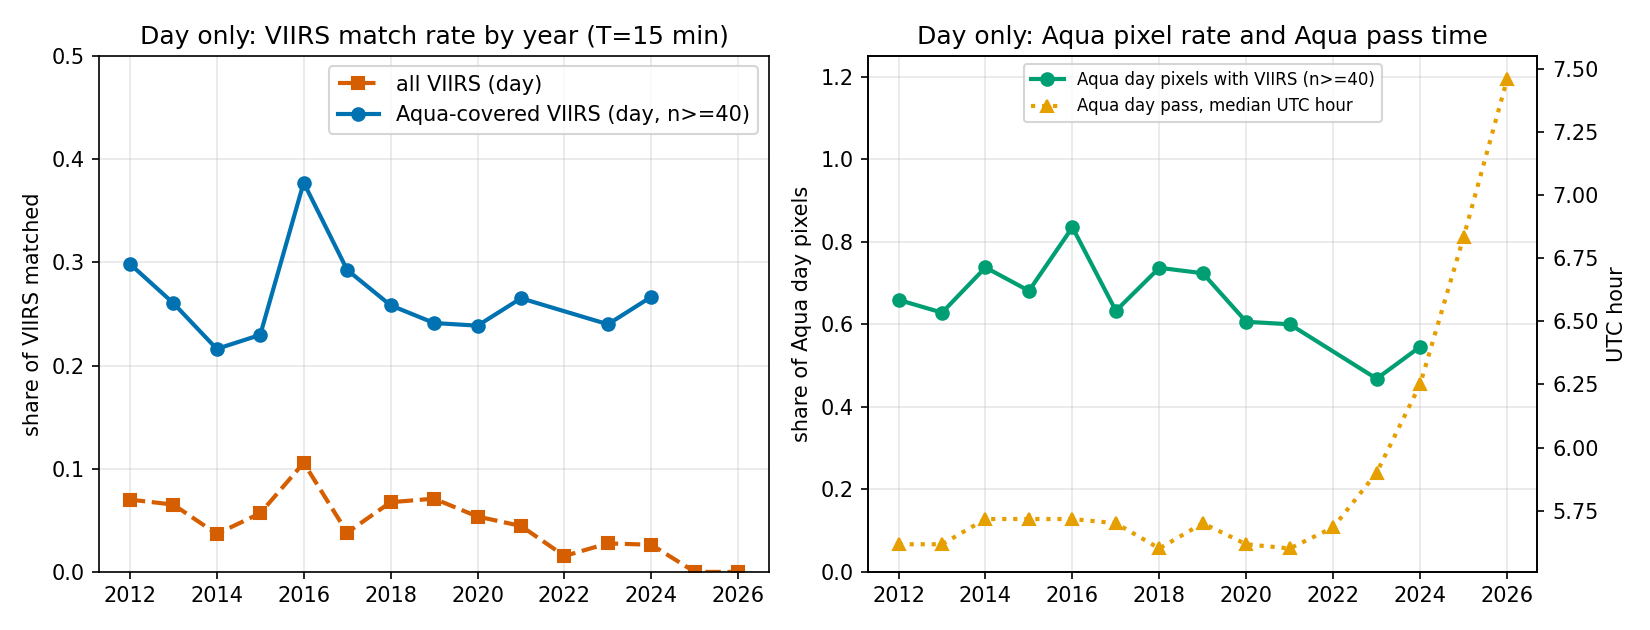

In [9]:
from IPython.display import Image, display
display(Image('figures/fig_match_by_year_day.png'))

## Phase 4 — Detection characteristics
Matched vs VIIRS-only: FRP, brightness, confidence, cluster size, acquisition time, with quartiles and tails. Match probability against FRP and cluster size. Reported for all VIIRS and for the Aqua-covered subset (Aqua detected something in the box within 15 min; a weak, detection-conditioned workaround).

In [10]:
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
pd.set_option('display.width', 220)
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': .3})
so = pd.read_csv('intermediate/p3_viirs_classified_T15.csv', parse_dates=['t'])
so['year'] = so.t.dt.year
P = so[so.year <= 2022]                       # primary period (Aqua overpass aligned)
C = P[P.aqua_obs]                             # Aqua-covered: Aqua detected a fire somewhere in the box within 15 min
FRP_BINS = [0, 2, 3, 4, 6, 8, 12, 20, 40, 1e9]; FRP_LAB = ['<2', '2-3', '3-4', '4-6', '6-8', '8-12', '12-20', '20-40', '40+']
CL_BINS = [0, 1, 2, 4, 9, 1e9]; CL_LAB = ['1', '2', '3-4', '5-9', '10+']

def desc(x, col):
    q = x[col].quantile([.1, .25, .5, .75, .9, .99])
    return pd.Series({'n': len(x), 'mean': x[col].mean(), 'p10': q[.1], 'q25': q[.25], 'med': q[.5], 'q75': q[.75], 'p90': q[.9], 'p99': q[.99]})

out = []
for samp, cond in (('all VIIRS', P), ('Aqua-covered', C)):
    for dn in 'DN':
        for col in ('frp', 'brightness', 'bright_t31', 'cl_n', 'cl_frp'):
            for mm, g in cond[cond.daynight == dn].groupby('matched'):
                r = desc(g, col); r['sample'] = samp; r['dn'] = dn; r['var'] = col; r['group'] = 'matched' if mm else 'VIIRS-only'; out.append(r)
D = pd.DataFrame(out); D.to_csv('intermediate/p4_distribution_stats.csv', index=False)
print(D[D['sample'] == 'Aqua-covered'].round(2)[['dn', 'var', 'group', 'n', 'mean', 'p10', 'q25', 'med', 'q75', 'p90', 'p99']].to_string(index=False))
print('\nALL VIIRS FRP/cl_n medians'); print(D[(D['sample'] == 'all VIIRS') & D['var'].isin(['frp', 'cl_n'])].round(2)[['dn', 'var', 'group', 'n', 'q25', 'med', 'q75', 'p90']].to_string(index=False))

# confidence, lone share, acquisition time
for samp, cond in (('all VIIRS', P), ('Aqua-covered', C)):
    print(f'\n[{samp}] confidence h share / lone-pixel share / median UTC minute-of-day')
    cond = cond.assign(lone=cond.cl_n == 1, mins=cond.t.dt.hour * 60 + cond.t.dt.minute)
    print(cond.groupby(['daynight', 'matched']).agg(n=('lone', 'size'), h_share=('confidence', lambda s: (s == 'h').mean()), lone=('lone', 'mean'), mins=('mins', 'median')).round(3).to_string())

# match probability by FRP bin and by cluster size (Aqua-covered, primary period)
for dn in 'DN':
    g = C[C.daynight == dn].assign(fb=lambda d: pd.cut(d.frp, FRP_BINS, labels=FRP_LAB), cb=lambda d: pd.cut(d.cl_n, CL_BINS, labels=CL_LAB))
    print(f'\n[{dn}] match prob by FRP bin'); print(g.groupby('fb', observed=True).matched.agg(['size', 'mean']).round(3).T.to_string())
    print(f'[{dn}] match prob by cluster size'); print(g.groupby('cb', observed=True).matched.agg(['size', 'mean']).round(3).T.to_string())
    if dn == 'D':
        t = g.groupby(['fb', 'cb'], observed=True).matched.agg(['size', 'mean']).reset_index()
        piv = t.pivot(index='fb', columns='cb', values='mean').round(2); nn = t.pivot(index='fb', columns='cb', values='size')
        print('\n[D] match prob: FRP bin (rows) x cluster size (cols); cells with n<20 blanked'); print(piv.where(nn >= 20).to_string())
        print('n per cell'); print(nn.to_string())
        piv.where(nn >= 20).to_csv('intermediate/p4_match_prob_frp_by_cluster_day.csv')
        # cluster-FRP (sum) too
        g2 = g.assign(sb=pd.cut(g.cl_frp, [0, 5, 10, 20, 50, 100, 200, 1e9], labels=['<5', '5-10', '10-20', '20-50', '50-100', '100-200', '200+']))
        print('[D] match prob by summed cluster FRP'); print(g2.groupby('sb', observed=True).matched.agg(['size', 'mean']).round(3).T.to_string())
# ambiguous (multi-Aqua) share and multiple VIIRS per Aqua pixel (Phase 3 requirement)
M = P[P.matched]; print('\nmatched VIIRS with >1 Aqua candidate:', (M.n_cand > 1).mean().round(3), ' of n', len(M))

# ---------- figures ----------
def ecdf(ax, x, **k):
    x = np.sort(x.values); ax.plot(x, np.arange(1, len(x) + 1) / len(x), **k)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, dn, ttl in zip(axs, 'DN', ('Day', 'Night')):
    for (samp, cond, col, ls) in (('Aqua-covered', C, OKABE[5], '-'), ('all VIIRS', P, OKABE[6], '--')):
        g = cond[cond.daynight == dn]
        ecdf(ax, g[g.matched].frp, color=col, ls=ls if samp == 'Aqua-covered' else ':', lw=2, label=f'matched ({samp}) n={int(g.matched.sum())}' if samp == 'Aqua-covered' else None)
        ecdf(ax, g[~g.matched].frp, color=OKABE[1] if samp == 'Aqua-covered' else OKABE[7], ls='--' if samp == 'Aqua-covered' else '-.', lw=2, label=f'VIIRS-only ({samp}) n={int((~g.matched).sum())}')
    ax.set_xscale('log'); ax.set_xlabel('VIIRS FRP (MW, log)'); ax.set_ylabel('cumulative share'); ax.set_title(f'{ttl}, 2012-2022, T=15 min'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/fig_frp_ecdf_matched_vs_viirsonly.png', dpi=150); plt.close()

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for dn, col, ls, mk in (('D', OKABE[5], '-', 'o'), ('N', OKABE[6], '--', 's')):
    g = C[C.daynight == dn].assign(fb=lambda d: pd.cut(d.frp, FRP_BINS, labels=FRP_LAB), cb=lambda d: pd.cut(d.cl_n, CL_BINS, labels=CL_LAB))
    for ax, key, labs in ((axs[0], 'fb', FRP_LAB), (axs[1], 'cb', CL_LAB)):
        r = g.groupby(key, observed=True).matched.agg(['size', 'mean']).reindex(labs)
        ok = r['size'] >= 20
        se = np.sqrt(r['mean'] * (1 - r['mean']) / r['size'])
        ax.errorbar(np.arange(len(labs))[ok.values], r['mean'][ok], yerr=1.96 * se[ok], color=col, ls=ls, marker=mk, lw=2, capsize=3, label={'D': 'Day', 'N': 'Night (bins with n>=20)'}[dn])
        ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs)
axs[0].set_xlabel('VIIRS FRP (MW)'); axs[1].set_xlabel('VIIRS pixels in cluster');
for ax in axs[:2]: ax.set_ylabel('share matched to an Aqua pixel'); ax.set_ylim(0, 1); ax.legend()
axs[0].set_title('Match probability vs FRP'); axs[1].set_title('Match probability vs cluster size')
g = C[C.daynight == 'D'].assign(fb=lambda d: pd.cut(d.frp, [0, 4, 8, 20, 1e9], labels=['<4', '4-8', '8-20', '20+']), cb=lambda d: pd.cut(d.cl_n, [0, 1, 4, 1e9], labels=['1 px', '2-4 px', '5+ px']))
for k, (lab, grp) in enumerate(g.groupby('cb', observed=True)):
    r = grp.groupby('fb', observed=True).matched.agg(['size', 'mean']); r = r[r['size'] >= 20]
    axs[2].plot([['<4', '4-8', '8-20', '20+'].index(i) for i in r.index], r['mean'], marker='o', lw=2, ls=LS[k], color=[OKABE[5], OKABE[3], OKABE[6]][k], label=f'cluster {lab}')
axs[2].set_xticks(range(4)); axs[2].set_xticklabels(['<4', '4-8', '8-20', '20+']); axs[2].set_xlabel('VIIRS FRP (MW)'); axs[2].set_ylabel('share matched'); axs[2].set_ylim(0, 1)
axs[2].set_title('Day: FRP effect within cluster size'); axs[2].legend()
plt.tight_layout(); plt.savefig('figures/fig_match_prob_frp_clustersize.png', dpi=150); plt.close()
print('figures written')


dn        var      group      n   mean    p10    q25    med    q75    p90    p99
 D        frp VIIRS-only 4216.0   7.84   2.78   3.86   5.57   8.49  13.98  45.81
 D        frp    matched 1643.0  14.51   4.23   5.74   9.02  16.53  31.46  68.56
 D brightness VIIRS-only 4216.0 337.62 330.25 332.59 336.37 341.36 346.54 355.92
 D brightness    matched 1643.0 341.16 331.62 334.48 340.26 345.94 352.32 367.00
 D bright_t31 VIIRS-only 4216.0 295.09 287.92 292.76 295.86 298.69 301.15 306.08
 D bright_t31    matched 1643.0 297.05 290.46 294.26 297.56 300.50 303.47 309.00
 D       cl_n VIIRS-only 4216.0   2.01   1.00   1.00   1.00   2.00   4.00  11.00
 D       cl_n    matched 1643.0   4.06   1.00   2.00   3.00   5.00   9.00  22.00
 D     cl_frp VIIRS-only 4216.0  19.97   3.08   4.53   8.41  17.66  40.24 241.90
 D     cl_frp    matched 1643.0  61.66   6.74  13.26  27.72  75.21 150.99 517.22
 N        frp VIIRS-only  189.0   1.35   0.60   0.80   1.12   1.67   2.16   4.85
 N        frp    matched  13

figures written


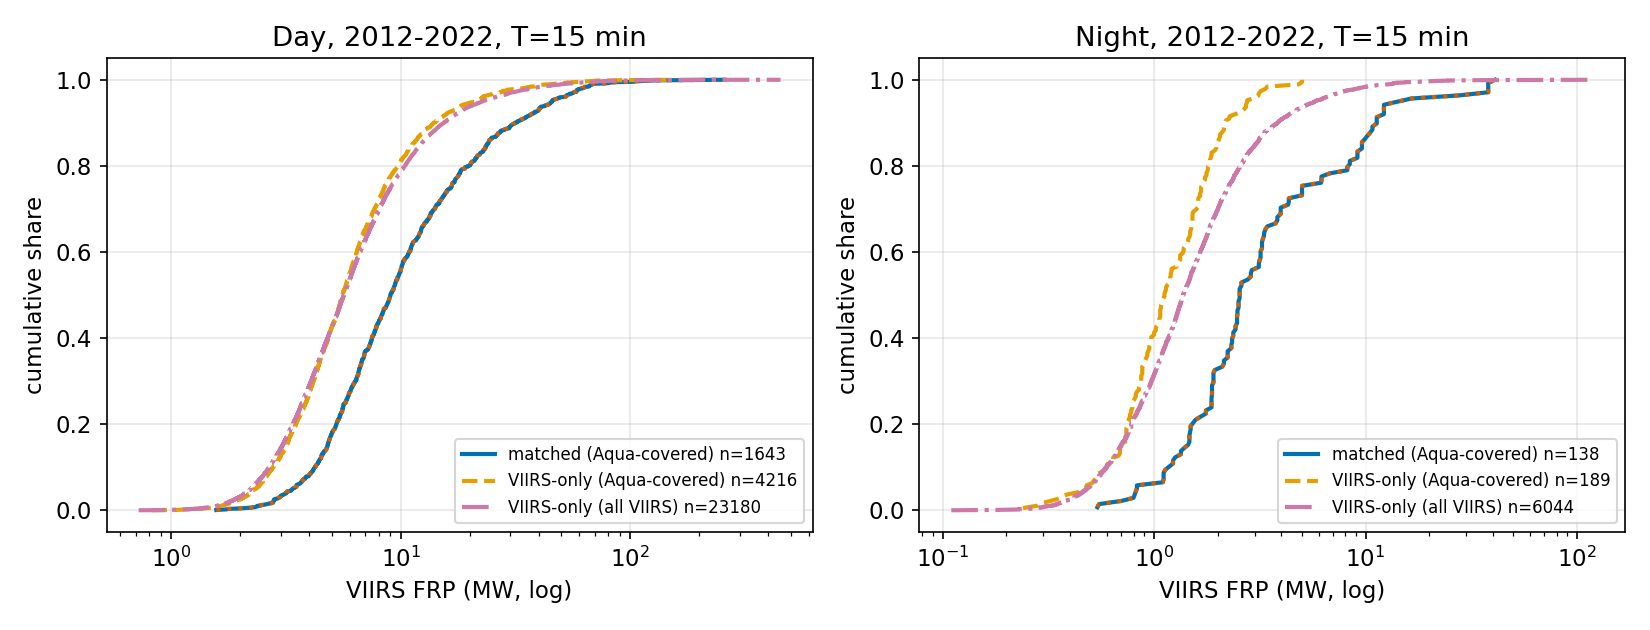

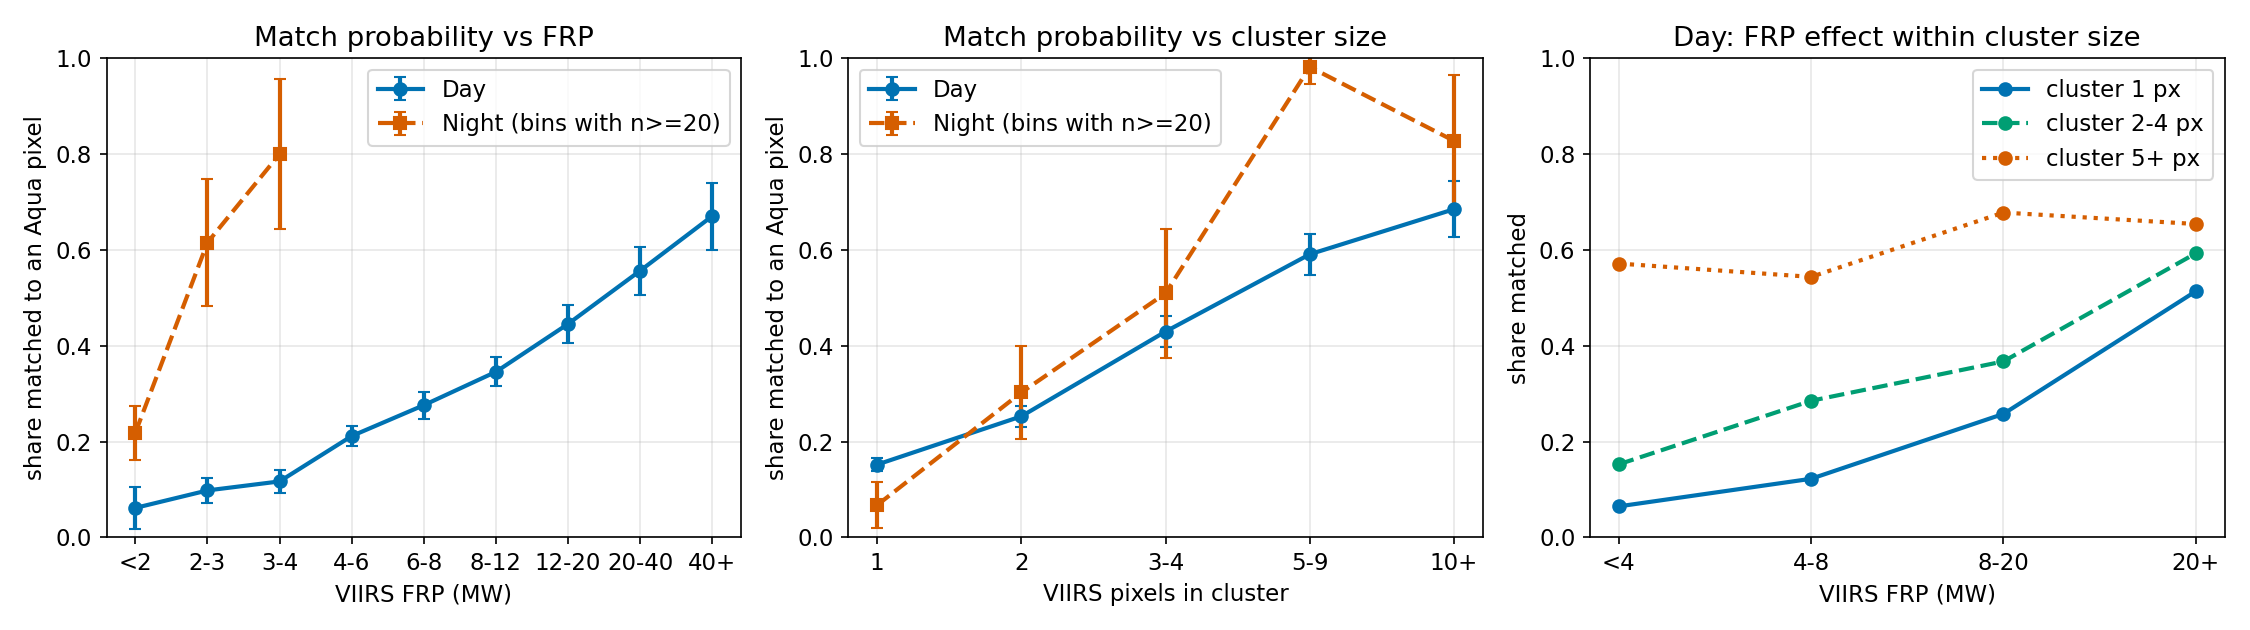

In [11]:
from IPython.display import Image, display
display(Image('figures/fig_frp_ecdf_matched_vs_viirsonly.png'))
display(Image('figures/fig_match_prob_frp_clustersize.png'))

### Phase 4b — Cluster-level matching and local-coverage check
A cluster counts as matched if any member matched, which removes the effect of several VIIRS pixels sharing one Aqua pixel. The local check asks for an Aqua detection within 20 km and 15 min.

In [12]:
from scipy.spatial import cKDTree
pd.set_option('display.width', 220)
so = pd.read_csv('intermediate/p3_viirs_classified_T15.csv', parse_dates=['t']); so = so[so.t < '2023-01-01'].copy()
ao = pd.read_csv('intermediate/p3_aqua_classified_T15.csv', parse_dates=['t']); ao = ao[ao.t < '2023-01-01'].copy()
# ---- cluster-level matching: cluster matched if any member matched ----
cl = so.groupby('cluster').agg(daynight=('daynight', 'first'), n=('cl_n', 'first'), frp_sum=('cl_frp', 'first'), frp_max=('frp', 'max'),
                              matched=('matched', 'max'), covered=('aqua_obs', 'max'), t=('t', 'first'))
print('clusters 2012-2022:', len(cl), ' matched', int(cl.matched.sum()), f'({cl.matched.mean():.3f})')
FB = [0, 4, 8, 20, 1e9]; FL = ['<4', '4-8', '8-20', '20+']; CB = [0, 1, 2, 4, 1e9]; CL = ['1 px', '2 px', '3-4 px', '5+ px']
for dn in 'DN':
    c = cl[(cl.daynight == dn) & cl.covered].assign(fb=lambda d: pd.cut(d.frp_max, FB, labels=FL), cb=lambda d: pd.cut(d.n, CB, labels=CL))
    print(f'\n[{dn}] Aqua-covered clusters n={len(c)}, matched {c.matched.mean():.3f}')
    print('by cluster size:'); print(c.groupby('cb', observed=True).matched.agg(['size', 'mean']).round(3).T.to_string())
    print('by max FRP in cluster:'); print(c.groupby('fb', observed=True).matched.agg(['size', 'mean']).round(3).T.to_string())
    if dn == 'D':
        t = c.groupby(['fb', 'cb'], observed=True).matched.agg(['size', 'mean']).reset_index()
        print('cluster-level match prob, max-FRP bin (rows) x cluster size (cols); n<15 blanked')
        p = t.pivot(index='fb', columns='cb', values='mean').round(2); n = t.pivot(index='fb', columns='cb', values='size')
        print(p.where(n >= 15).to_string()); print(n.to_string()); p.where(n >= 15).to_csv('intermediate/p4b_cluster_level_day.csv')
        print('cluster-level lone share: matched vs VIIRS-only', c.groupby('matched').n.apply(lambda s: (s == 1).mean()).round(3).to_dict(), ' median max-FRP', c.groupby('matched').frp_max.median().round(2).to_dict())
# ---- local-coverage check: VIIRS-only pixels with any Aqua detection within 15 min AND within 20 km ----
sx, sy = km_xy(so.latitude, so.longitude); ax, ay = km_xy(ao.latitude, ao.longitude)
tree = cKDTree(np.c_[ax, ay]); at = ao.t.values.astype('datetime64[s]').astype('int64') / 60; st = so.t.values.astype('datetime64[s]').astype('int64') / 60
near = tree.query_ball_point(np.c_[sx, sy], 20.0)
so['local_cov20'] = [bool(len(j) and (np.abs(at[j] - st[i]) <= 15).any()) for i, j in enumerate(near)]
so['cl_lone'] = so.cl_n == 1
for dn in 'DN':
    g = so[so.daynight == dn]; vo = g[~g.matched]
    print(f'\n[{dn}] all VIIRS n={len(g)}; VIIRS-only n={len(vo)}')
    print('  VIIRS-only with ANY Aqua detection in box within 15 min (covered):', vo.aqua_obs.mean().round(3), ' with Aqua detection within 20 km AND 15 min:', vo.local_cov20.mean().round(3))
    l = g[g.local_cov20]
    print(f'  local-covered (<=20 km, <=15 min): n={len(l)}, match rate {l.matched.mean():.3f}; lone share matched/VIIRS-only:', l.groupby('matched').cl_lone.mean().round(3).to_dict(), ' FRP median matched/VIIRS-only:', l.groupby('matched').frp.median().round(2).to_dict())
so[['latitude', 'longitude', 't', 'daynight', 'matched', 'aqua_obs', 'local_cov20', 'cl_n', 'frp']].to_csv('intermediate/p4b_viirs_local_cov.csv', index=False)
print('\nfootprint uses each detection own scan x track (FIRMS fields): Aqua day scan/track median', ao.scan.median(), ao.track.median(), ' p90', ao.scan.quantile(.9), ao.track.quantile(.9))


clusters 2012-2022: 20331  matched 834 (0.041)

[D] Aqua-covered clusters n=3816, matched 0.209
by cluster size:
cb        1 px     2 px   3-4 px    5+ px
size  2667.000  776.000  272.000  101.000
mean     0.152    0.258    0.463    0.644
by max FRP in cluster:
fb         <4       4-8     8-20      20+
size  965.000  1548.000  968.000  335.000
mean    0.067     0.149    0.317    0.576
cluster-level match prob, max-FRP bin (rows) x cluster size (cols); n<15 blanked
cb    1 px  2 px  3-4 px  5+ px
fb                             
<4    0.06  0.09     NaN    NaN
4-8   0.12  0.17    0.39    NaN
8-20  0.26  0.30    0.48   0.63
20+   0.51  0.61    0.58   0.70
cb      1 px   2 px  3-4 px  5+ px
fb                                
<4     866.0   91.0     8.0    NaN
4-8   1129.0  327.0    82.0   10.0
8-20   524.0  273.0   130.0   41.0
20+    148.0   85.0    52.0   50.0
cluster-level lone share: matched vs VIIRS-only {False: 0.749, True: 0.509}  median max-FRP {False: 5.42, True: 10.09}

[N] Aqua-


[D] all VIIRS n=24823; VIIRS-only n=23180
  VIIRS-only with ANY Aqua detection in box within 15 min (covered): 0.182  with Aqua detection within 20 km AND 15 min: 0.05
  local-covered (<=20 km, <=15 min): n=2805, match rate 0.586; lone share matched/VIIRS-only: {False: 0.465, True: 0.247}  FRP median matched/VIIRS-only: {False: 5.74, True: 9.02}

[N] all VIIRS n=6182; VIIRS-only n=6044
  VIIRS-only with ANY Aqua detection in box within 15 min (covered): 0.031  with Aqua detection within 20 km AND 15 min: 0.008
  local-covered (<=20 km, <=15 min): n=184, match rate 0.750; lone share matched/VIIRS-only: {False: 0.37, True: 0.051}  FRP median matched/VIIRS-only: {False: 1.27, True: 2.54}



footprint uses each detection own scan x track (FIRMS fields): Aqua day scan/track median 1.2 1.1  p90 2.1 1.4


## Phase 5 — Quiet vs busy
Months ranked by cleaned VIIRS count (Feb 2012 – Oct 2026) into four quarters. Monthly ratios, ratios of sums and the Terra + Aqua vs Aqua-only ratios are kept separate. Matching comparisons use 2012–2022 only. Standardised rates are model predictions, not observations.

In [13]:
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
pd.set_option('display.width', 230)
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': .3})
mc = pd.read_csv(os.path.join(DATA, 'monthly_counts.csv'))
mc['ym'] = pd.to_datetime(dict(year=mc.year, month=mc.month, day=1)).dt.to_period('M')
mc = mc[(mc.ym >= '2012-02') & (mc.ym <= '2026-10')].copy()
mc['viirs'] = mc.viirs.fillna(0)
print('months Feb 2012-Oct 2026:', len(mc), ' VIIRS NaN-filled:', mc.viirs.isna().sum())
# quarters by rank of cleaned VIIRS count (ties broken by order)
mc['rank'] = mc.viirs.rank(method='first')
mc['quarter'] = pd.qcut(mc['rank'], 4, labels=['Q1 quietest', 'Q2', 'Q3', 'Q4 busiest'])
edges = mc.groupby('quarter', observed=True).viirs.agg(['min', 'max', 'count', 'sum', 'median'])
print(edges.to_string())
mc['ratio_terra_aqua'] = mc.viirs / (mc.modis_terra + mc.modis_aqua).replace(0, np.nan)
mc['ratio_aqua'] = mc.viirs / mc.modis_aqua.replace(0, np.nan)
mc.to_csv('intermediate/p5_month_quarters.csv', index=False)
# ratios kept separate
rr = mc.groupby('quarter', observed=True).apply(lambda g: pd.Series({
    'ratio_of_sums_TerraAqua': g.viirs.sum() / (g.modis_terra + g.modis_aqua).sum(),
    'mean_monthly_ratio_TerraAqua': g.ratio_terra_aqua.mean(),
    'ratio_of_sums_AquaOnly': g.viirs.sum() / g.modis_aqua.sum(),
    'mean_monthly_ratio_AquaOnly': g.ratio_aqua.mean(), 'months_with_zero_aqua': int((g.modis_aqua == 0).sum())}))
print('\nRATIOS (count level; separate definitions)'); print(rr.round(2).to_string()); rr.to_csv('intermediate/p5_ratios_by_quarter.csv')

so = pd.read_csv('intermediate/p3_viirs_classified_T15.csv', parse_dates=['t']); so['ym'] = so.t.dt.to_period('M')
so = so.merge(mc[['ym', 'quarter']], on='ym', how='left')
so = so[so.t < '2023-01-01']                       # drift period excluded from the comparison
print('\nVIIRS detections in primary period:', len(so), ' months per quarter (<=2022):', mc[mc.ym < '2023-01'].groupby('quarter', observed=True).size().to_dict())
Q = so.assign(lone=so.cl_n == 1)
rows = []
for dn in ('D', 'N'):
    for q, g in Q[Q.daynight == dn].groupby('quarter', observed=True):
        c = g[g.aqua_obs]
        rows.append(dict(dn=dn, quarter=q, n_viirs=len(g), match_rate_all=g.matched.mean(), share_aqua_covered=g.aqua_obs.mean(), n_covered=len(c),
                         match_rate_covered=c.matched.mean() if len(c) else np.nan, viirs_only_share_covered=(1 - c.matched.mean()) if len(c) else np.nan,
                         frp_q25=g.frp.quantile(.25), frp_med=g.frp.median(), frp_q75=g.frp.quantile(.75), lone_share=g.lone.mean(), cl_med=g.cl_n.median(),
                         frp_med_cov=c.frp.median() if len(c) else np.nan, lone_cov=c.lone.mean() if len(c) else np.nan, cl_med_cov=c.cl_n.median() if len(c) else np.nan))
T5 = pd.DataFrame(rows); T5.to_csv('intermediate/p5_quiet_busy_table.csv', index=False)
print('\nQUIET vs BUSY (2012-2022, T=15; covered = Aqua detected something in box within 15 min)'); print(T5.round(3).to_string(index=False))
# Aqua-side: share of Aqua pixels with VIIRS (when VIIRS-covered), by quarter
ao = pd.read_csv('intermediate/p3_aqua_classified_T15.csv', parse_dates=['t']); ao['ym'] = ao.t.dt.to_period('M'); ao = ao.merge(mc[['ym', 'quarter']], on='ym', how='left'); ao = ao[ao.t < '2023-01-01']
A = ao[ao.viirs_obs].groupby(['daynight', 'quarter'], observed=True).has_viirs.agg(['size', 'mean']).round(3); print('\nAqua pixels containing VIIRS | VIIRS covered, by quarter'); print(A.to_string())
print('all Aqua detections by quarter (<=2022):', ao.groupby('quarter', observed=True).size().to_dict())

# standardisation (day, covered): predicted match rate if each quarter's (FRP bin x cluster class) mix had the pooled match probabilities
FB = [0, 2, 3, 4, 6, 8, 12, 20, 40, 1e9]; CB = [0, 1, 2, 4, 9, 1e9]
g = Q[(Q.daynight == 'D') & Q.aqua_obs].copy()
g['cell'] = pd.cut(g.frp, FB).astype(str) + '|' + pd.cut(g.cl_n, CB).astype(str)
pool = g.groupby('cell').matched.mean(); g['pred'] = g.cell.map(pool)
S = g.groupby('quarter', observed=True).agg(n=('matched', 'size'), observed=('matched', 'mean'), predicted_from_mix=('pred', 'mean'))
print('\nSTANDARDISATION day covered: observed vs rate predicted from FRPxcluster mix alone'); print(S.round(3).to_string()); S.to_csv('intermediate/p5_standardisation_day.csv')
# bootstrap CI on observed per-quarter covered match rate (resampling clusters would be better; resample passes)
rng = np.random.default_rng(0); ci = {}
for q, gq in g.groupby('quarter', observed=True):
    pid = gq.groupby('pass_id').matched.agg(['sum', 'size']); b = []
    for _ in range(500):
        k = pid.sample(len(pid), replace=True, random_state=int(rng.integers(1e9))); b.append(k['sum'].sum() / k['size'].sum())
    ci[q] = np.percentile(b, [2.5, 97.5]).round(3)
print('pass-bootstrap 95% CI, day covered match rate:', {k: v.tolist() for k, v in ci.items()})
# ECDF of FRP by quarter (day, all VIIRS)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2)); cols = [OKABE[5], OKABE[3], OKABE[1], OKABE[6]]
for k, (q, gq) in enumerate(Q[Q.daynight == 'D'].groupby('quarter', observed=True)):
    x = np.sort(gq.frp.values); axs[0].plot(x, np.arange(1, len(x) + 1) / len(x), color=cols[k], ls=LS[k], lw=2, label=f'{q} (n={len(x)})')
axs[0].set_xscale('log'); axs[0].set_xlabel('VIIRS FRP (MW, log)'); axs[0].set_ylabel('cumulative share'); axs[0].set_title('Day FRP by activity quarter'); axs[0].legend(fontsize=8)
d = T5[T5.dn == 'D']; x = np.arange(4)
axs[1].plot(x, d.match_rate_covered, marker='o', color=OKABE[5], ls='-', lw=2, label='Aqua-covered VIIRS')
axs[1].plot(x, d.match_rate_all, marker='s', color=OKABE[6], ls='--', lw=2, label='all VIIRS')
axs[1].plot(x, S.predicted_from_mix.values, marker='^', color=OKABE[3], ls=':', lw=2, label='predicted from FRPxcluster mix (covered)')
axs[1].set_xticks(x); axs[1].set_xticklabels(['Q1\nquietest', 'Q2', 'Q3', 'Q4\nbusiest']); axs[1].set_ylabel('match rate'); axs[1].set_ylim(0, .6); axs[1].legend(fontsize=8); axs[1].set_title('Day match rate by quarter (2012-2022)')
axs[2].plot(x, d.lone_share, marker='o', color=OKABE[5], ls='-', lw=2, label='lone-pixel share'); axs[2].plot(x, d.share_aqua_covered, marker='s', color=OKABE[1], ls='--', lw=2, label='share Aqua-covered')
axs[2].set_xticks(x); axs[2].set_xticklabels(['Q1\nquietest', 'Q2', 'Q3', 'Q4\nbusiest']); axs[2].set_ylim(0, 1); axs[2].legend(fontsize=8); axs[2].set_title('Day: isolation and coverage by quarter')
plt.tight_layout(); plt.savefig('figures/fig_quiet_vs_busy.png', dpi=150); plt.close(); print('figure written')


months Feb 2012-Oct 2026: 177  VIIRS NaN-filled: 0
               min     max  count      sum  median
quarter                                           
Q1 quietest    3.0    56.0     45   1386.0    31.0
Q2            57.0   111.0     44   3462.0    75.5
Q3           113.0   253.0     44   7693.0   167.0
Q4 busiest   264.0  2432.0     44  24236.0   413.5

RATIOS (count level; separate definitions)
             ratio_of_sums_TerraAqua  mean_monthly_ratio_TerraAqua  ratio_of_sums_AquaOnly  mean_monthly_ratio_AquaOnly  months_with_zero_aqua
quarter                                                                                                                                       
Q1 quietest                     6.73                          9.46                    8.30                        11.99                   10.0
Q2                              5.96                          7.93                    7.56                        10.90                    0.0
Q3                         


VIIRS detections in primary period: 31005  months per quarter (<=2022): {'Q1 quietest': 29, 'Q2': 31, 'Q3': 33, 'Q4 busiest': 38}

QUIET vs BUSY (2012-2022, T=15; covered = Aqua detected something in box within 15 min)
dn     quarter  n_viirs  match_rate_all  share_aqua_covered  n_covered  match_rate_covered  viirs_only_share_covered  frp_q25  frp_med  frp_q75  lone_share  cl_med  frp_med_cov  lone_cov  cl_med_cov
 D Q1 quietest      781           0.029               0.110         86               0.267                     0.733     3.05     4.53    6.400       0.640     1.0         4.68     0.686         1.0
 D          Q2     2058           0.030               0.119        245               0.253                     0.747     3.22     4.79    7.627       0.601     1.0         4.95     0.645         1.0
 D          Q3     5303           0.058               0.224       1190               0.260                     0.740     3.64     5.50    9.255       0.536     1.0         6.05     0.


STANDARDISATION day covered: observed vs rate predicted from FRPxcluster mix alone
                n  observed  predicted_from_mix
quarter                                        
Q1 quietest    86     0.267               0.219
Q2            245     0.253               0.190
Q3           1190     0.260               0.244
Q4 busiest   4338     0.288               0.297


pass-bootstrap 95% CI, day covered match rate: {'Q1 quietest': [0.174, 0.36], 'Q2': [0.199, 0.307], 'Q3': [0.218, 0.302], 'Q4 busiest': [0.248, 0.327]}


figure written


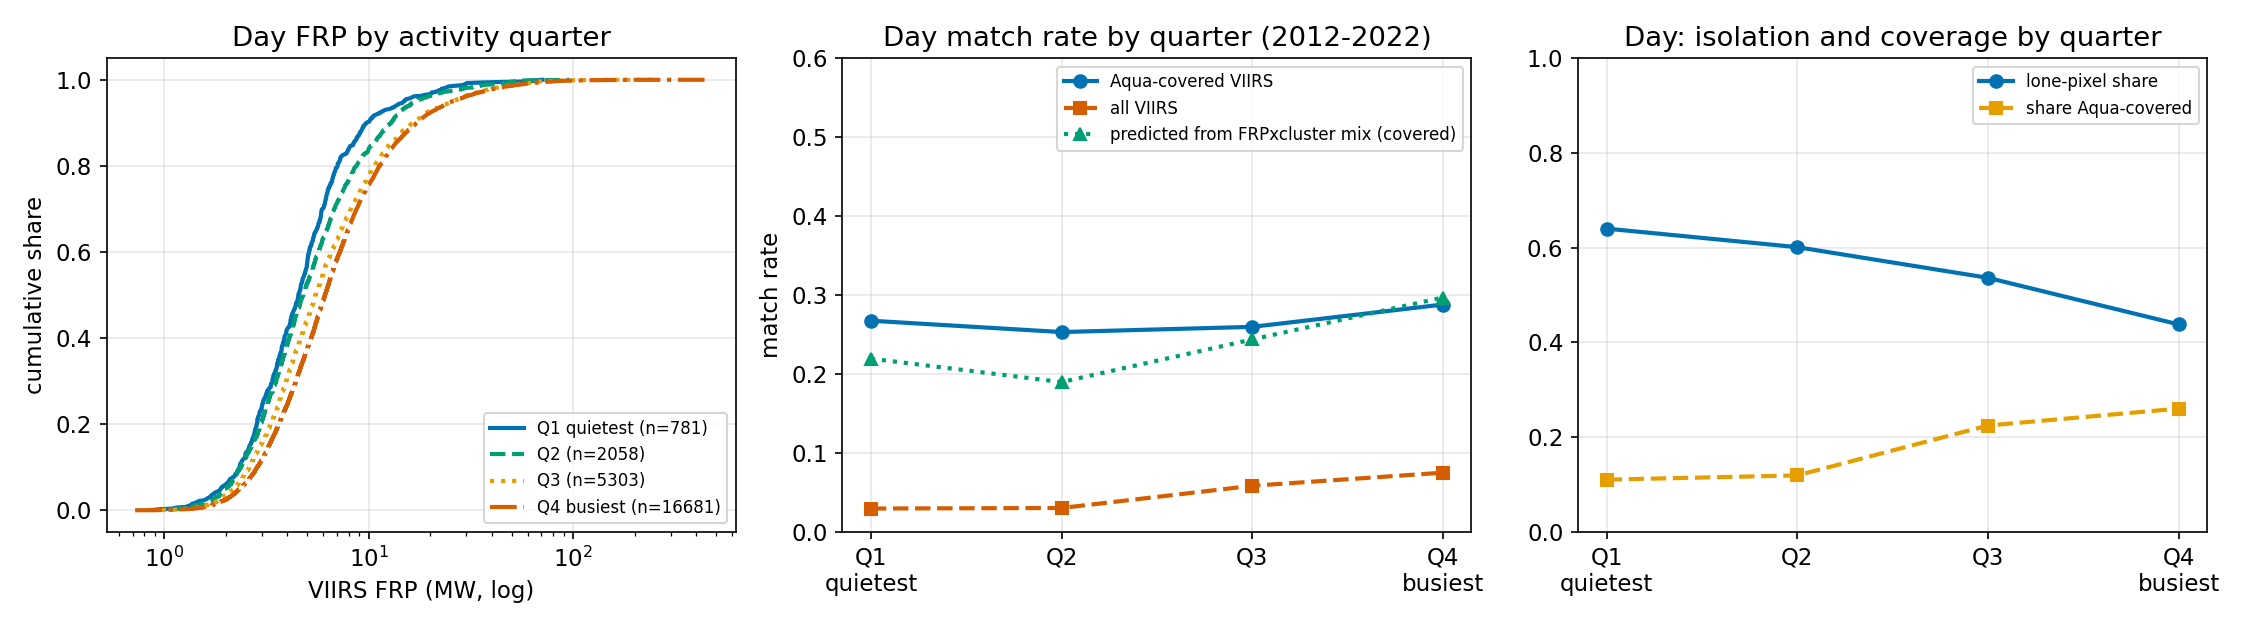

In [14]:
from IPython.display import Image, display
display(Image('figures/fig_quiet_vs_busy.png'))

## Phase 6 — Robustness
Spatial rule and margin, time threshold, duplicate removal, FRP outliers, sparse months, cluster link, stricter confidence, near-nadir Aqua. Question: do the main conclusions stay stable? (Contrasts yes; absolute match rate 18–31% no.)

In [15]:
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
pd.set_option('display.width', 240)
m, v = load_raw(); a0, s0 = clean(m, v)
END = '2023-01-01'                                   # primary period only
a0 = a0[a0.t < END]; s0 = s0[s0.t < END]
mc = pd.read_csv('intermediate/p5_month_quarters.csv'); mc['ym'] = pd.PeriodIndex(mc.ym, freq='M'); qmap = mc.set_index('ym').quarter

def metrics(a, s, T=15, mode='rect', scale=1.0, margin=0.5, link=0.75, label=''):
    s = add_clusters(s, link); so, ao = match(a, s, T=T, mode=mode, scale=scale, margin=margin)
    so['q'] = so.t.dt.to_period('M').map(qmap); d = so[so.daynight == 'D']; c = d[d.aqua_obs]; lone = c.cl_n == 1
    mm, vo = c[c.matched], c[~c.matched]
    r = dict(variant=label, n_day_viirs=len(d), n_covered=len(c), match_cov=c.matched.mean(),
             frp_med_matched=mm.frp.median(), frp_med_only=vo.frp.median(), lone_matched=(mm.cl_n == 1).mean(), lone_only=(vo.cl_n == 1).mean(),
             p_frp_lt4=c[c.frp < 4].matched.mean(), p_frp_ge20=c[c.frp >= 20].matched.mean(),
             p_lone=c[lone].matched.mean(), p_5plus=c[c.cl_n >= 5].matched.mean())
    for q, tag in (('Q1 quietest', 'Q1'), ('Q4 busiest', 'Q4')):
        dq = d[d.q == q]; r[f'lone_all_{tag}'] = (dq.cl_n == 1).mean(); r[f'frp_med_all_{tag}'] = dq.frp.median()
        cq = dq[dq.aqua_obs]; r[f'match_cov_{tag}'] = cq.matched.mean(); r[f'n_cov_{tag}'] = len(cq)
        r[f'match_all_{tag}'] = dq.matched.mean(); r[f'share_cov_{tag}'] = dq.aqua_obs.mean()
    ao_d = ao[(ao.daynight == 'D') & ao.viirs_obs]; r['aqua_pix_rate_viirsobs'] = ao_d.has_viirs.mean()
    return r

rows = [metrics(a0, s0, label='BASE (T15, rect, margin .5, link .75)')]
rows += [metrics(a0, s0, scale=1.5, label='footprint x1.5'), metrics(a0, s0, mode='radius', label='fixed radius 1 km'),
         metrics(a0, s0, margin=0.0, label='margin 0 km'), metrics(a0, s0, margin=1.0, label='margin 1.0 km')]
rows += [metrics(a0, s0, T=T, label=f'T={T} min') for T in (5, 30, 60)]
rows += [metrics(a0, s0, link=l, label=f'cluster link {l} km') for l in (0.5, 1.0)]
# FRP outliers: drop top 1% FRP of each sensor
rows.append(metrics(a0[a0.frp <= a0.frp.quantile(.99)], s0[s0.frp <= s0.frp.quantile(.99)], label='drop top 1% FRP (both)'))
# stricter confidence
rows.append(metrics(a0[a0.conf_num >= 50], s0, label='Aqua conf >= 50'))
rows.append(metrics(a0, s0[s0.confidence == 'h'], label='VIIRS conf h only'))
# duplicate removal: collapse same-pass VIIRS detections at identical rounded (0.001 deg) coordinates; Aqua same
s_dd = s0.drop_duplicates(['acq_date', 'acq_time', s0.latitude.round(3).rename('la'), s0.longitude.round(3).rename('lo')]) if False else s0.assign(la=s0.latitude.round(3), lo=s0.longitude.round(3)).drop_duplicates(['acq_date', 'acq_time', 'la', 'lo'])
a_dd = a0.assign(la=a0.latitude.round(3), lo=a0.longitude.round(3)).drop_duplicates(['acq_date', 'acq_time', 'la', 'lo'])
print('rounded-coordinate duplicates removed: VIIRS', len(s0) - len(s_dd), 'Aqua', len(a0) - len(a_dd))
rows.append(metrics(a_dd, s_dd, label='duplicates removed (0.001 deg)'))
# sparse months: drop months with <30 VIIRS detections
cnt = s0.groupby(s0.t.dt.to_period('M')).size(); ok = cnt[cnt >= 30].index
rows.append(metrics(a0[a0.t.dt.to_period('M').isin(ok)], s0[s0.t.dt.to_period('M').isin(ok)], label='drop months with <30 VIIRS (sparse)'))
# swath-scan-angle: keep only Aqua pixels with scan<=1.5 km (near nadir)
rows.append(metrics(a0[a0.scan <= 1.5], s0, label='Aqua scan <= 1.5 km (near nadir)'))
R = pd.DataFrame(rows); R.to_csv('intermediate/p6_robustness.csv', index=False)
cols1 = ['variant', 'n_covered', 'match_cov', 'frp_med_matched', 'frp_med_only', 'lone_matched', 'lone_only', 'p_frp_lt4', 'p_frp_ge20', 'p_lone', 'p_5plus', 'aqua_pix_rate_viirsobs']
cols2 = ['variant', 'lone_all_Q1', 'lone_all_Q4', 'frp_med_all_Q1', 'frp_med_all_Q4', 'match_cov_Q1', 'n_cov_Q1', 'match_cov_Q4', 'match_all_Q1', 'match_all_Q4', 'share_cov_Q1', 'share_cov_Q4']
print(R[cols1].round(3).to_string(index=False)); print(); print(R[cols2].round(3).to_string(index=False))
# figure: match rate vs time threshold (rect/x1.5/radius, day covered, primary period)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sc = add_clusters(s0, 0.75)
for k, (mode, scale, lab, col) in enumerate((('rect', 1.0, 'rect x1.0', OKABE[5]), ('rect', 1.5, 'rect x1.5', OKABE[3]), ('radius', 1.0, 'radius 1 km', OKABE[6]))):
    xs, y1, y2 = [], [], []
    for T in (5, 15, 30, 60):
        so, ao = match(a0, sc, T=T, mode=mode, scale=scale); d = so[so.daynight == 'D']
        xs.append(T); y1.append(d[d.aqua_obs].matched.mean()); y2.append(ao[(ao.daynight == 'D') & ao.viirs_obs].has_viirs.mean())
    ax[0].plot(xs, y1, marker='o', lw=2, ls=LS[k], color=col, label=lab); ax[1].plot(xs, y2, marker='o', lw=2, ls=LS[k], color=col, label=lab)
ax[0].set_title('Day: share of Aqua-covered VIIRS matched'); ax[1].set_title('Day: share of Aqua pixels containing VIIRS\n(S-NPP observed box within T)')
for x in ax: x.set_xlabel('time threshold T (min)'); x.set_ylim(0, 1); x.set_xticks([5, 15, 30, 60]); x.legend()
plt.tight_layout(); plt.savefig('figures/fig_match_rate_vs_time_threshold.png', dpi=150); plt.close(); print('figure written')


rounded-coordinate duplicates removed: VIIRS 134 Aqua 0


                              variant  n_covered  match_cov  frp_med_matched  frp_med_only  lone_matched  lone_only  p_frp_lt4  p_frp_ge20  p_lone  p_5plus  aqua_pix_rate_viirsobs
BASE (T15, rect, margin .5, link .75)       5859      0.280            9.020         5.570         0.247      0.537      0.105       0.592   0.152    0.621                   0.701
                       footprint x1.5       5859      0.301            8.940         5.540         0.244      0.546      0.114       0.612   0.161    0.674                   0.734
                    fixed radius 1 km       5859      0.247            8.940         5.705         0.255      0.521      0.094       0.502   0.138    0.522                   0.610
                          margin 0 km       5859      0.182            9.290         5.830         0.244      0.502      0.066       0.403   0.097    0.422                   0.447
                        margin 1.0 km       5859      0.306            8.935         5.530         0

figure written


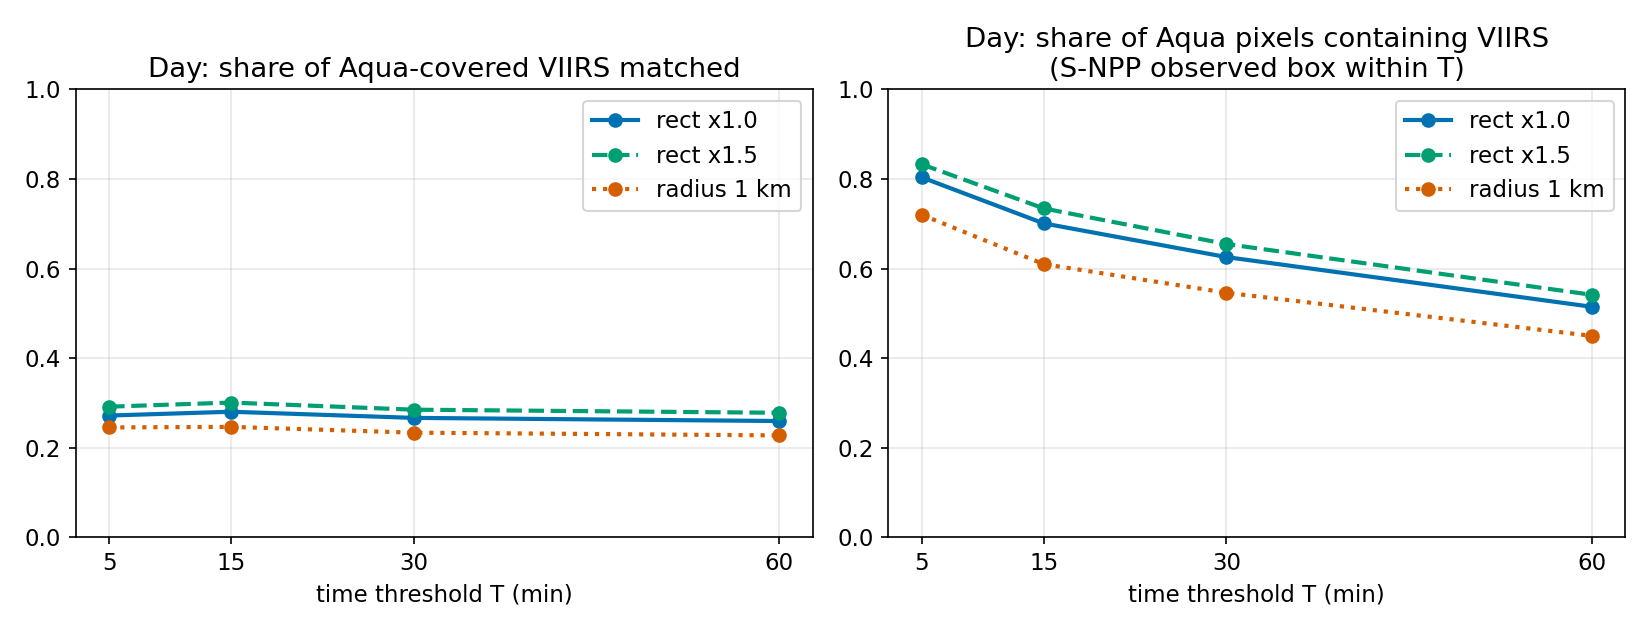

In [16]:
from IPython.display import Image, display
display(Image('figures/fig_match_rate_vs_time_threshold.png'))

## Phase 7 — Optional activity-dependent count correction
Uses the existing hold-out (learn Feb 2012 – Dec 2018, test 2019–2025). The baseline must reproduce first (24.3% total error, 79.8% uncorrected, 31.8% per-calendar-month ratio, 23.5% straight line, ~86% colour class). The single pre-declared power-law correction must beat 24.3% and 86% to count as an improvement.

In [17]:
pd.set_option('display.width', 200)
mc = pd.read_csv(os.path.join(DATA, 'monthly_counts.csv'))
mc['ym'] = pd.to_datetime(dict(year=mc.year, month=mc.month, day=1)).dt.to_period('M')
mc = mc[(mc.ym >= '2012-02') & (mc.ym <= '2026-10')].copy()
mc['modis'] = mc.modis_terra + mc.modis_aqua
learn = mc[(mc.ym >= '2012-02') & (mc.ym <= '2018-12')]; test = mc[(mc.ym >= '2019-01') & (mc.ym <= '2025-12')]
print('learn months', len(learn), 'test months', len(test), 'test viirs NaN', test.viirs.isna().sum(), 'modis_raw vs terra+aqua equal:', (mc.modis_raw == mc.modis).mean().round(3))
r = learn.viirs.sum() / learn.modis.sum(); print('learned ratio of sums (Terra+Aqua)', round(r, 3))
def defs(pred, y, tag):
    y = y.values.astype(float); p = np.asarray(pred, float)
    print(f'{tag:34s} WAPE {np.abs(p - y).sum() / y.sum():.3f} | |sum err| {abs(p.sum() - y.sum()) / y.sum():.3f} | median APE {np.median(np.abs(p - y) / np.maximum(y, 1)):.3f} | mean APE {np.mean(np.abs(p - y) / np.maximum(y, 1)):.3f}')
defs(r * test.modis, test.viirs, 'ratio of sums x MODIS')
defs(test.modis, test.viirs, 'no correction (VIIRS=MODIS)')
# per-calendar-month ratio
cm = learn.groupby('month').apply(lambda g: g.viirs.sum() / g.modis.sum()); defs(test.month.map(cm) * test.modis, test.viirs, 'per-calendar-month ratio')
# straight-line fit viirs ~ a + b*modis
b, a_ = np.polyfit(learn.modis, learn.viirs, 1); defs(a_ + b * test.modis, test.viirs, 'straight-line fit')
print('test: sum viirs', test.viirs.sum(), 'sum modis', test.modis.sum(), 'test ratio of sums', round(test.viirs.sum() / test.modis.sum(), 3))


learn months 83 test months 84 test viirs NaN 0 modis_raw vs terra+aqua equal: 1.0
learned ratio of sums (Terra+Aqua) 4.922
ratio of sums x MODIS              WAPE 0.243 | |sum err| 0.008 | median APE 0.329 | mean APE 0.399
no correction (VIIRS=MODIS)        WAPE 0.798 | |sum err| 0.798 | median APE 0.822 | mean APE 0.825
per-calendar-month ratio           WAPE 0.318 | |sum err| 0.037 | median APE 0.415 | mean APE 0.459
straight-line fit                  WAPE 0.235 | |sum err| 0.006 | median APE 0.323 | mean APE 0.356
test: sum viirs 11274.0 sum modis 2273 test ratio of sums 4.96


In [18]:
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
mc = pd.read_csv(os.path.join(DATA, 'monthly_counts.csv'))
mc['ym'] = pd.to_datetime(dict(year=mc.year, month=mc.month, day=1)).dt.to_period('M')
mc = mc[(mc.ym >= '2012-02') & (mc.ym <= '2026-10')].copy(); mc['modis'] = mc.modis_terra + mc.modis_aqua
learn = mc[mc.ym <= '2018-12']; test = mc[(mc.ym >= '2019-01') & (mc.ym <= '2025-12')]
EDGES = [74, 204, 376]
cls = lambda x: np.digitize(np.asarray(x, float), EDGES, right=False)     # 4 classes
wape = lambda p, y: np.abs(np.asarray(p, float) - y).sum() / y.sum()
agree = lambda p, y: (cls(p) == cls(y)).mean()
y = test.viirs.values.astype(float)
r = learn.viirs.sum() / learn.modis.sum()
res = {}
res['ratio of sums (baseline)'] = r * test.modis.values
b1, a1 = np.polyfit(learn.modis, learn.viirs, 1); res['straight line (baseline)'] = a1 + b1 * test.modis.values
# edge convention check for the baseline 86%
for right in (False, True):
    c = lambda x: np.digitize(np.asarray(x, float), EDGES, right=right)
    print('edge right=%s agreement of ratio-of-sums:' % right, (c(res['ratio of sums (baseline)']) == c(y)).mean().round(3))
# pre-declared correction: power law  viirs = k * modis^b  (log-log OLS on months with modis>0 and viirs>0), smearing correction
L = learn[(learn.modis > 0) & (learn.viirs > 0)]
b, la = np.polyfit(np.log(L.modis), np.log(L.viirs), 1); resid = np.log(L.viirs) - (la + b * np.log(L.modis)); smear = np.exp(resid).mean()
print(f'power law fit (learn n={len(L)}): viirs = {np.exp(la):.3f} * modis^{b:.3f}; smearing {smear:.3f}; implied ratio at modis=5: {np.exp(la)*5**(b-1):.2f}, 50: {np.exp(la)*50**(b-1):.2f}, 500: {np.exp(la)*500**(b-1):.2f}')
pl = np.where(test.modis.values > 0, smear * np.exp(la) * np.maximum(test.modis.values, 1e-9) ** b, np.nan)
res['power law (activity-dependent)'] = np.where(np.isnan(pl), r * test.modis.values, pl)    # months with 0 MODIS fall back to ratio
print('test months with modis==0:', int((test.modis == 0).sum()))
out = pd.DataFrame({k: {'WAPE (total error)': wape(v, y), 'colour-class agreement': agree(v, y), '|sum error|': abs(np.sum(v) - y.sum()) / y.sum()} for k, v in res.items()}).T
print(out.round(3).to_string()); out.round(4).to_csv('intermediate/p7_correction_holdout.csv')
print('targets to beat: WAPE < 0.243 AND class agreement > 0.86')
# class agreement by quiet class and error by quarter of test months
q = pd.qcut(test.viirs.rank(method='first'), 4, labels=['Q1', 'Q2', 'Q3', 'Q4']).values
for k, v in res.items():
    print(k, 'WAPE by test-activity quarter:', {qq: round(wape(v[q == qq], y[q == qq]), 3) for qq in ('Q1', 'Q2', 'Q3', 'Q4')}, ' signed bias (pred-actual)/actual:', {qq: round((v[q == qq].sum() - y[q == qq].sum()) / y[q == qq].sum(), 3) for qq in ('Q1', 'Q2', 'Q3', 'Q4')})
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(learn.modis, learn.viirs, s=14, color=OKABE[5], label='learn 2012-2018'); ax.scatter(test.modis, test.viirs, s=14, color=OKABE[6], marker='s', label='test 2019-2025')
xx = np.linspace(1, learn.modis.max() * 1.3, 200); ax.plot(xx, r * xx, color=OKABE[0], ls='--', lw=2, label=f'ratio {r:.2f}'); ax.plot(xx, smear * np.exp(la) * xx ** b, color=OKABE[3], ls='-', lw=2, label=f'power law b={b:.2f}')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('MODIS (Terra+Aqua) monthly count'); ax.set_ylabel('VIIRS monthly count'); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig('figures/fig_correction_holdout.png', dpi=150)


edge right=False agreement of ratio-of-sums: 0.857
edge right=True agreement of ratio-of-sums: 0.857
power law fit (learn n=83): viirs = 12.029 * modis^0.776; smearing 1.070; implied ratio at modis=5: 8.39, 50: 5.02, 500: 3.00
test months with modis==0: 7
                                WAPE (total error)  colour-class agreement  |sum error|
ratio of sums (baseline)                     0.243                   0.857        0.008
straight line (baseline)                     0.235                   0.857        0.006
power law (activity-dependent)               0.259                   0.798        0.098
targets to beat: WAPE < 0.243 AND class agreement > 0.86
ratio of sums (baseline) WAPE by test-activity quarter: {'Q1': np.float64(0.662), 'Q2': np.float64(0.378), 'Q3': np.float64(0.303), 'Q4': np.float64(0.179)}  signed bias (pred-actual)/actual: {'Q1': np.float64(-0.161), 'Q2': np.float64(-0.249), 'Q3': np.float64(-0.0), 'Q4': np.float64(0.039)}
straight line (baseline) WAPE by test-act

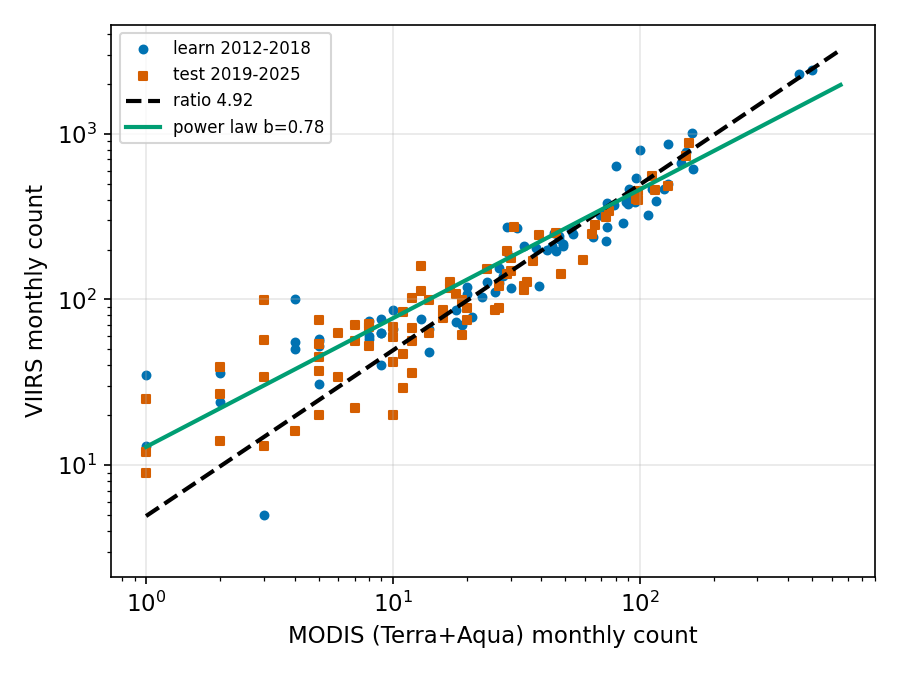

In [19]:
from IPython.display import Image, display
display(Image('figures/fig_correction_holdout.png'))

## Extra figures
Measured overpass-gap histogram (left panel day, right panel night) and match rate by year (Aqua drift). `fig_match_by_year.png` pools day + night match rates (the Aqua pass-time overlay is the day pass); the day-only version is shown in the day/night audit above.

In [20]:
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': .3})
# (1) measured Aqua-S-NPP overpass gap (Phase 1)
g = pd.read_csv('intermediate/p1_gaps.csv', parse_dates=['t'])
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, dn, ttl in zip(axs, 'DN', ('Day', 'Night')):
    for per, col, ls in (('2012-2022', OKABE[5], '-'), ('2023+', OKABE[6], '--')):
        x = g[(g.dn == dn) & (g.period == per)].gap
        if len(x): ax.hist(x, bins=np.arange(-120, 121, 10), histtype='step', lw=2, ls=ls, color=col, density=True, label=f'{per} (n={len(x)})')
    ax.axvspan(-15, 15, color='0.85', zorder=0); ax.set_xlabel('Aqua minus S-NPP pass time (min), nearest Aqua pass'); ax.set_title(f'{ttl}: gap to nearest Aqua pass'); ax.legend()
axs[0].set_ylabel('density'); plt.tight_layout(); plt.savefig('figures/fig_overpass_gap_hist.png', dpi=150); plt.close()
# (2) match rate by year (T=15), Aqua drift
yr = pd.read_csv('intermediate/p3_by_year_T15.csv')
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ok = yr.n_aqobs >= 40
ax[0].plot(yr.year, yr.match_rate, marker='s', ls='--', lw=2, color=OKABE[6], label='all VIIRS')
ax[0].plot(yr.year[ok], yr.match_rate_aqobs[ok], marker='o', ls='-', lw=2, color=OKABE[5], label='Aqua-covered VIIRS (n>=40)')
ax[0].set_ylim(0, .5); ax[0].set_ylabel('share of VIIRS matched'); ax[0].legend(); ax[0].set_title('VIIRS match rate by year (T=15 min)')
ok2 = yr.n_aqua_viirsobs >= 40
ax[1].plot(yr.year[ok2], yr.aqua_pix_rate_viirsobs[ok2], marker='o', ls='-', lw=2, color=OKABE[3], label='Aqua pixels with VIIRS (n>=40)')
a = pd.read_csv('intermediate/p1_aqua_passes.csv', parse_dates=['tmed']); d = a[a.daynight == 'D']; mm = d.groupby(d.tmed.dt.year).apply(lambda x: (x.tmed.dt.hour * 60 + x.tmed.dt.minute).median() / 60)
ax2 = ax[1].twinx(); ax2.plot(mm.index, mm.values, marker='^', ls=':', lw=2, color=OKABE[1], label='Aqua day pass, median UTC hour'); ax2.set_ylabel('UTC hour'); ax2.grid(False)
ax[1].set_ylim(0, 1.25); ax[1].set_ylabel('share of Aqua pixels'); ax[1].set_title('Aqua pixel rate and Aqua pass time'); h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax[1].legend(h1 + h2, l1 + l2, fontsize=8, loc='upper center')
plt.tight_layout(); plt.savefig('figures/fig_match_by_year.png', dpi=150); plt.close(); print('ok')


ok


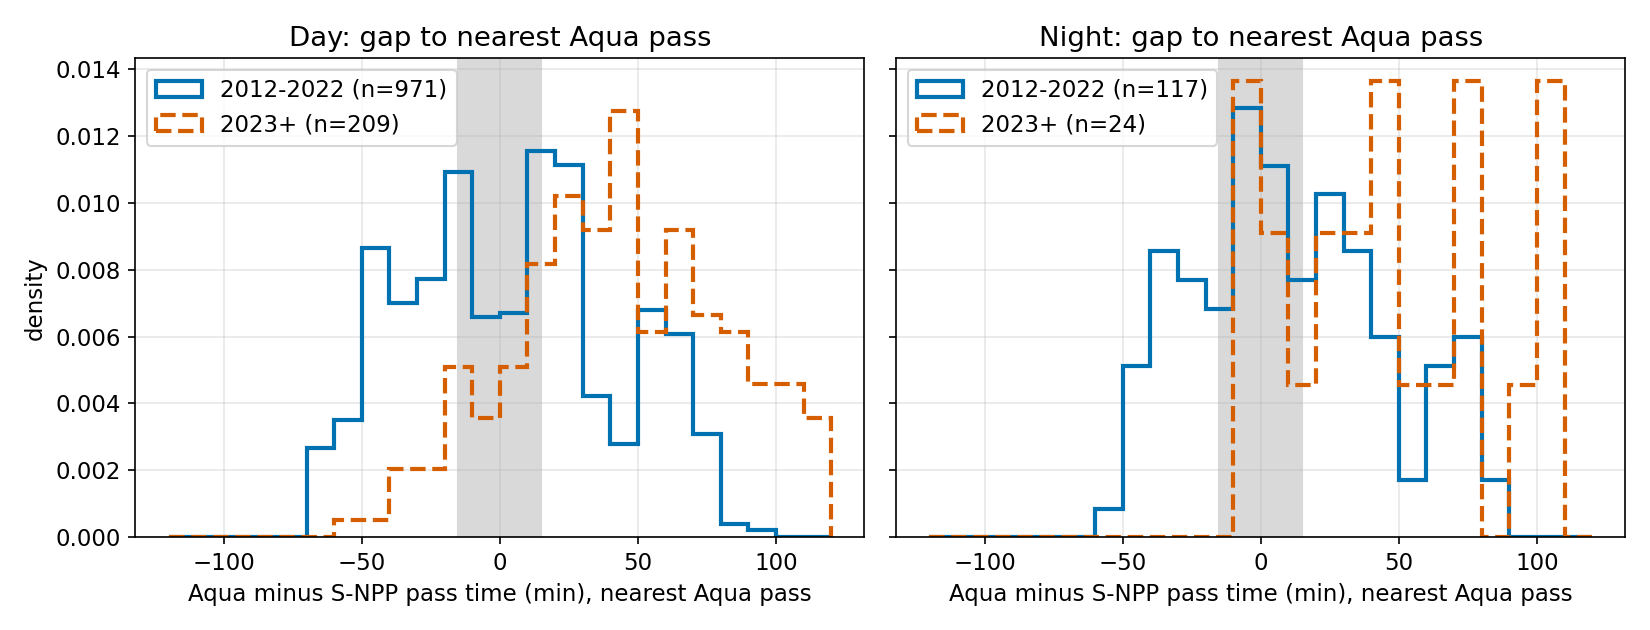

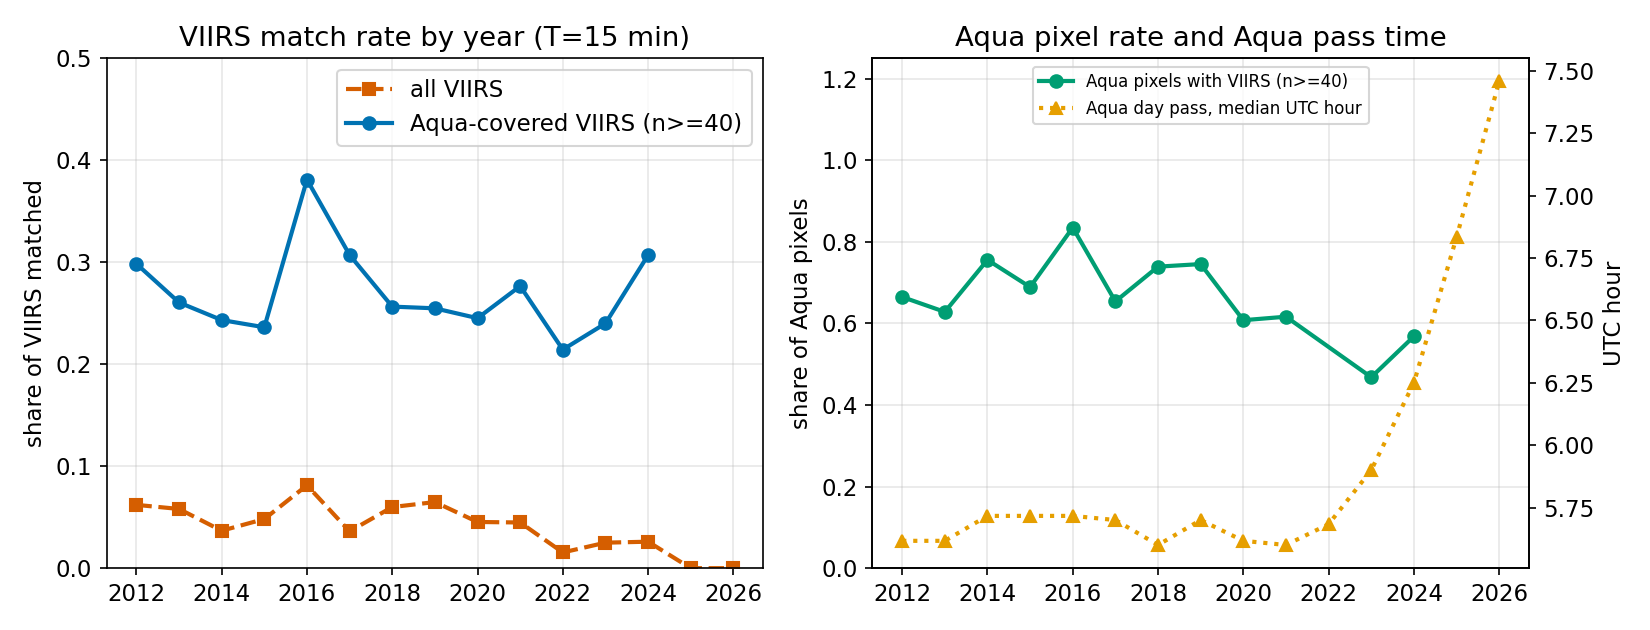

In [21]:
from IPython.display import Image, display
display(Image('figures/fig_overpass_gap_hist.png'))
display(Image('figures/fig_match_by_year.png'))